# Assignment: Explainable AI for Time Series Forecasting

**Dataset:** Beijing PM2.5 air quality, 2010–2014 (Liang et al., 2015, UCI Machine Learning Repository)

## 0. Setup

In [1]:
!pip install shap lime lightgbm statsmodels torch scikit-learn pandas matplotlib seaborn scipy

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("shap", shap.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)

shap 0.54.1 | lightgbm 4.6.0 | torch 2.11.0+cpu


## Dataset

Hourly PM2.5 concentration at the US Embassy in Beijing, with weather from Beijing Capital Airport: 43,824 hours. You will aggregate to **daily** values (1,826 days) and forecast **tomorrow's mean PM2.5 (µg/m³)**.

| Column | Meaning | Daily aggregation |
|---|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³), **target** | mean |
| `DEWP` | Dew point (°C), a humidity proxy | mean |
| `TEMP` | Temperature (°C) | mean |
| `PRES` | Air pressure (hPa) | mean |
| `cbwd` | Combined wind direction: NW, NE, SE, cv (calm/variable) | most frequent |
| `Iws` | Cumulated wind speed (m/s) | max |
| `Is` | Cumulated hours of snow | max |
| `Ir` | Cumulated hours of rain | max |

**Chronological split (fixed for everyone):** train 2010–2012, validation 2013 (early stopping only), test 2014. Compute every explanation on the 2014 test year.

**Domain hints.** Beijing pollution builds up over several stagnant, humid days and is flushed out by strong, dry north-westerly winds. Winter heating raises baseline levels. These are your *sanity prior*.

The starter code below is provided; run it as given.

In [3]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
raw = pd.read_csv(URL)
raw["date"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw = raw.set_index("date").drop(columns=["No", "year", "month", "day", "hour"])

daily = raw.resample("D").agg({
    "pm2.5": "mean", "DEWP": "mean", "TEMP": "mean", "PRES": "mean",
    "Iws": "max", "Is": "max", "Ir": "max",
    "cbwd": lambda s: s.mode().iloc[0] if len(s.mode()) else np.nan,
})
print(daily.shape, "|", daily["pm2.5"].isna().sum(), "days without PM2.5")
daily.head()

(1826, 8) | 37 days without PM2.5


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd
date,,,,,,,,
2010-01-01,NaN,-18.750000,-6.750000,1017.083333,43.82,0,0,NW
2010-01-02,145.958333,-8.500000,-5.125000,1024.750000,55.43,4,0,SE
2010-01-03,78.833333,-10.125000,-8.541667,1022.791667,127.84,27,0,SE
2010-01-04,31.333333,-20.875000,-11.500000,1029.291667,198.45,0,0,NW
2010-01-05,42.458333,-24.583333,-14.458333,1033.625000,218.57,0,0,NW


In [4]:
def metrics(y_true, y_pred):
    """MAE and RMSE. Always call this with values in µg/m³."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

---
# Part A: Exploration and a sanity prior
Build the prior that your explanations will be checked against later.

### A1
Handle the 37 days with no PM2.5 reading. Write code that compares two strategies, **linear interpolation** and **forward fill**, and justify the one you keep. Explain why you must never fill gaps using values from the future *when building features*.

Missing days: 37
Longest run of consecutive missing days: 5
First valid date: 2010-01-02

Backtest MAE on hidden 1-3 day gaps (288 gaps):  interpolation = 42.79   forward fill = 56.24 ug/m3

                mean    std  skew
observed only  98.65  77.55  1.62
interpolated   98.56  77.09  1.62
forward fill   98.09  77.22  1.62


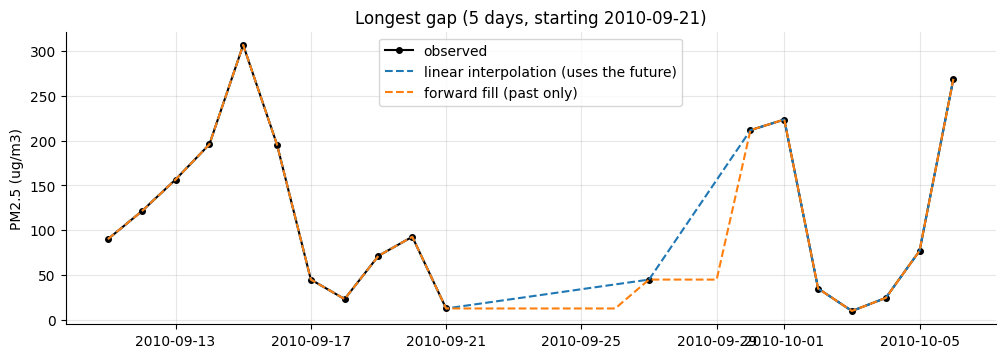


Remaining NaNs in daily_clean:
 pm2.5    0
DEWP     0
TEMP     0
PRES     0
Iws      0
Is       0
Ir       0
cbwd     0


In [5]:
# A1: compare linear interpolation vs forward fill, then build the cleaned series.
pm_raw = daily["pm2.5"]
print("Missing days:", pm_raw.isna().sum())
print("Longest run of consecutive missing days:",
      (pm_raw.isna().astype(int).groupby((~pm_raw.isna()).cumsum()).sum()).max())
print("First valid date:", pm_raw.first_valid_index().date())

pm_interp = pm_raw.interpolate(method="linear", limit_direction="both")   # uses the NEXT valid reading
pm_ffill  = pm_raw.ffill().bfill()                                         # uses only the past (bfill only touches leading days)

# (i) Backtest: hide random blocks of 1-3 days from days that were observed, fill them back, measure error.
rng = np.random.default_rng(SEED)
obs_idx = np.where(~pm_raw.isna().values)[0]
errs = {"interp": [], "ffill": []}
for _ in range(300):
    start = rng.choice(obs_idx[10:-10]); L = rng.integers(1, 4)
    block = np.arange(start, start + L)
    if pm_raw.iloc[block].isna().any() or pm_raw.iloc[start-1:start+L+1].isna().any():
        continue
    s = pm_raw.copy(); s.iloc[block] = np.nan
    truth = pm_raw.iloc[block].values
    errs["interp"].append(np.abs(s.interpolate().iloc[block].values - truth).mean())
    errs["ffill"].append(np.abs(s.ffill().iloc[block].values - truth).mean())
print(f"\nBacktest MAE on hidden 1-3 day gaps ({len(errs['interp'])} gaps):  "
      f"interpolation = {np.mean(errs['interp']):.2f}   forward fill = {np.mean(errs['ffill']):.2f} ug/m3")

# (ii) Summary statistics of the three versions
summ = pd.DataFrame({"observed only": pm_raw, "interpolated": pm_interp, "forward fill": pm_ffill}).agg(["mean", "std", "skew"]).T.round(2)
print(); print(summ)

# (iii) Plot both fills around the longest gap
run_id = (~pm_raw.isna()).cumsum()
run_len = pm_raw.isna().groupby(run_id).transform("sum")
gap_days = int(run_len.max()); gap_first = run_len[run_len == gap_days].index[0]
win = slice(gap_first - pd.Timedelta(days=10), gap_first + pd.Timedelta(days=gap_days + 10))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(pm_raw[win], "ko-", label="observed", ms=4)
ax.plot(pm_interp[win], "--", color="tab:blue", label="linear interpolation (uses the future)")
ax.plot(pm_ffill[win],  "--", color="tab:orange", label="forward fill (past only)")
ax.set_title(f"Longest gap ({gap_days} days, starting {gap_first.date()})"); ax.set_ylabel("PM2.5 (ug/m3)"); ax.legend(); plt.show()

# Decision: keep forward fill. It is causal, so a value at day t never depends on anything after t.
pm_clean = pm_ffill
daily_clean = daily.copy()
daily_clean["pm2.5"] = pm_clean
print("\nRemaining NaNs in daily_clean:\n", daily_clean.isna().sum().to_string())

**A1 — Your answer:**

I hid 288 random 1–3 day blocks of observed data and filled them back: linear interpolation had a MAE of 42.79 µg/m³ and forward fill 56.24 µg/m³. The summary statistics are almost identical (mean 98.56 interpolated vs 98.09 forward-filled vs 98.65 observed; skew 1.62 in all three), and only 37 of 1,826 days are missing (longest gap 5 days), so the choice barely matters for the distribution. I keep **forward fill**, because it is causal: the value filled on day *t* depends only on days ≤ *t*. Interpolation is more accurate inside a gap (about 13 µg/m³ better) but it draws a line towards the *next* reading, so a feature built on day *t−1* would silently contain information about day *t* or later and inflate test skill exactly on the gap days. The single leading NaN (2010-01-01) is back-filled once; after cleaning there are 0 missing values.

### A2
Plot daily PM2.5 for 2010–2014 with a 30-day rolling mean. Then plot its histogram and that of `log1p(PM2.5)`. Report the skewness of both and decide whether to model the **raw** or the **log** target. State how this choice will change the *units* of every SHAP value you report later.

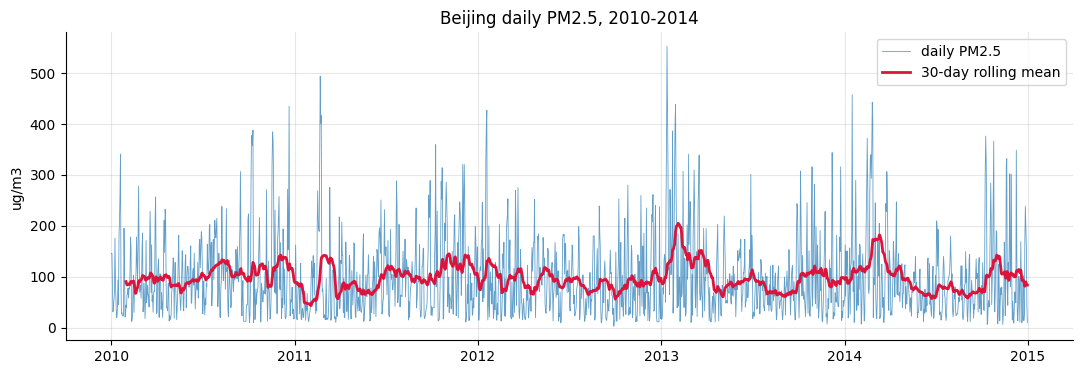

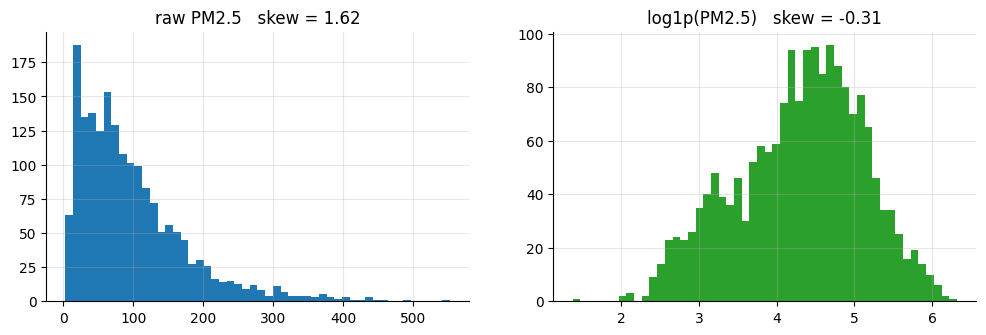

Skewness raw = 1.622 | log1p = -0.311
Mean 98.1, median 78.9, max 552.5 ug/m3
Days above 75 ug/m3: 0.527 | above 250: 93
USE_LOG_TARGET = True


In [6]:
# A2: time plot, histograms, skewness.
pm = daily_clean["pm2.5"]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(pm, lw=0.6, alpha=0.7, label="daily PM2.5")
ax.plot(pm.rolling(30).mean(), color="crimson", lw=2, label="30-day rolling mean")
ax.set_ylabel("ug/m3"); ax.set_title("Beijing daily PM2.5, 2010-2014"); ax.legend(); plt.show()

sk_raw, sk_log = pm.skew(), np.log1p(pm).skew()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(pm, bins=50, color="tab:blue");  axes[0].set_title(f"raw PM2.5   skew = {sk_raw:.2f}")
axes[1].hist(np.log1p(pm), bins=50, color="tab:green"); axes[1].set_title(f"log1p(PM2.5)   skew = {sk_log:.2f}")
plt.show()
print(f"Skewness raw = {sk_raw:.3f} | log1p = {sk_log:.3f}")
print(f"Mean {pm.mean():.1f}, median {pm.median():.1f}, max {pm.max():.1f} ug/m3")
print("Days above 75 ug/m3:", (pm > 75).mean().round(3), "| above 250:", (pm > 250).sum())

USE_LOG_TARGET = True   # |skew(log1p)| is smaller than |skew(raw)|; we model log1p(PM2.5)
print("USE_LOG_TARGET =", USE_LOG_TARGET)

**A2 — Your answer:**

Daily PM2.5 averages 98.1 µg/m³ (median 78.9, max 552.5) and 52.7% of days exceed the 75 µg/m³ standard; the 30-day mean peaks every winter. The raw series has skewness 1.62, while log1p(PM2.5) has −0.31, so the log is far closer to symmetric and I set `USE_LOG_TARGET = True`. This changes the **units of every SHAP value to log1p(µg/m³)**: SHAP values add up on the log scale, so a value φ is a *multiplicative* effect (φ = +0.10 means roughly +10% on 1 + PM2.5), not a number of µg/m³. The SHAP base value of 4.286 log units therefore translates to 71.7 µg/m³, below the arithmetic mean of 98.1 because it is a geometric-type average.

### A3
Run an STL decomposition (period 365) on your chosen target. Report the share of variance in the seasonal and residual components. Compare with the temperature series from the lecture (66.9% seasonal): is pollution more or less predictable from the calendar alone? Explain why physically.

{'Trend': '0.4%', 'Seasonal': '61.7%', 'Residual': '73.0%'} | sum of shares = 135.1%
Normalised so the three shares add to 100%: {'Trend': '0.3%', 'Seasonal': '45.6%', 'Residual': '54.1%'}
corr(seasonal, residual) = -0.259 (STL does not force the components to be uncorrelated, so raw ratios need not add to 100%)
Lag-1 autocorrelation of the STL residual: 0.415


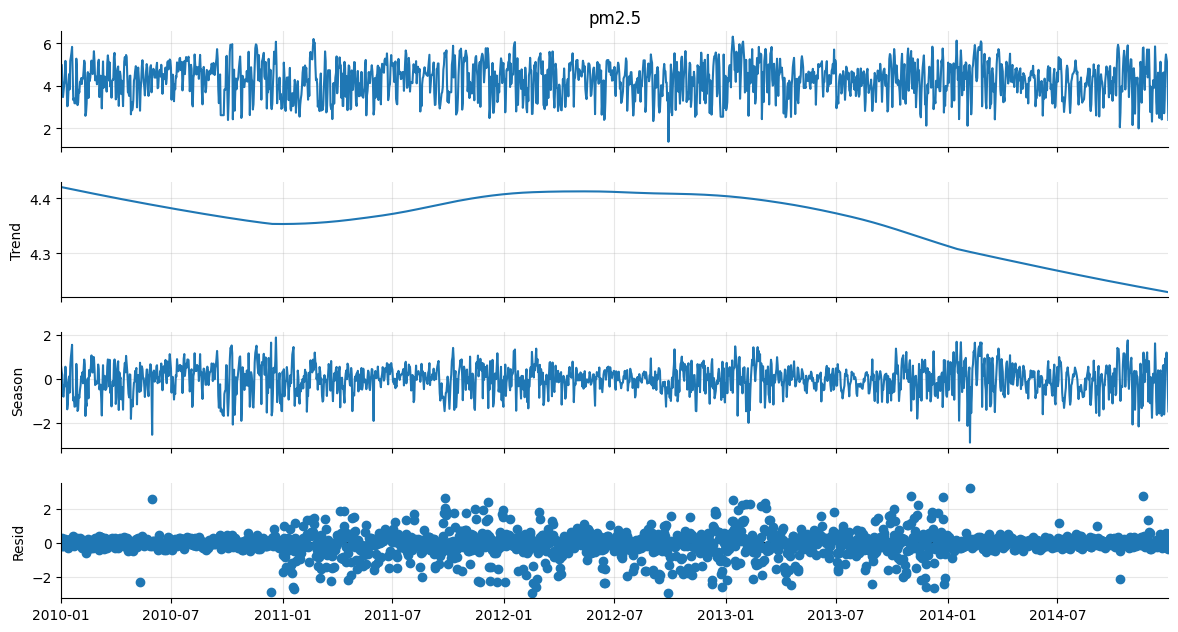

In [7]:
# A3: STL decomposition (period 365) of the chosen target.
y_target = np.log1p(daily_clean["pm2.5"]) if USE_LOG_TARGET else daily_clean["pm2.5"]
stl = STL(y_target, period=365, robust=True).fit()
v = y_target.var()
share = {"Trend": stl.trend.var() / v, "Seasonal": stl.seasonal.var() / v, "Residual": stl.resid.var() / v}
print({k: f"{100*x:.1f}%" for k, x in share.items()}, "| sum of shares =", f"{100*sum(share.values()):.1f}%")
tot = sum(share.values())
print("Normalised so the three shares add to 100%:", {k: f"{100*x/tot:.1f}%" for k, x in share.items()})
print("corr(seasonal, residual) =", round(np.corrcoef(stl.seasonal, stl.resid)[0, 1], 3),
      "(STL does not force the components to be uncorrelated, so raw ratios need not add to 100%)")
print("Lag-1 autocorrelation of the STL residual:", round(stl.resid.autocorr(1), 3))

fig = stl.plot(); fig.set_size_inches(12, 7); plt.show()

**A3 — Your answer:**

On log1p(PM2.5), STL with period 365 gives variance ratios of 61.7% seasonal, 73.0% residual and 0.4% trend. They add up to 135.1% because the seasonal and residual parts are negatively correlated (−0.259), so normalised to 100% the split is 45.6% seasonal and 54.1% residual. Compared with 66.9% seasonal for the lecture's temperature series, pollution is clearly **less predictable from the calendar alone**. The residual is also persistent (lag-1 autocorrelation 0.415), meaning it consists of multi-day episodes. Physically, temperature follows the sun's deterministic annual cycle, whereas PM2.5 follows heating emissions (a seasonal baseline) plus stagnation and frontal passages that are weather-driven and last a few days.

### A4
1. Plot the ACF and PACF of the target up to lag 30.
2. Compute the Spearman correlation between **tomorrow's** PM2.5 and **today's** value of each weather variable (`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`).
3. Show the mean next-day PM2.5 by today's wind direction (`cbwd`).

From these results, write down your **sanity prior**: a ranked list of the 4–5 inputs you expect a faithful explanation to put at the top, with the expected sign (+ / −) of each.

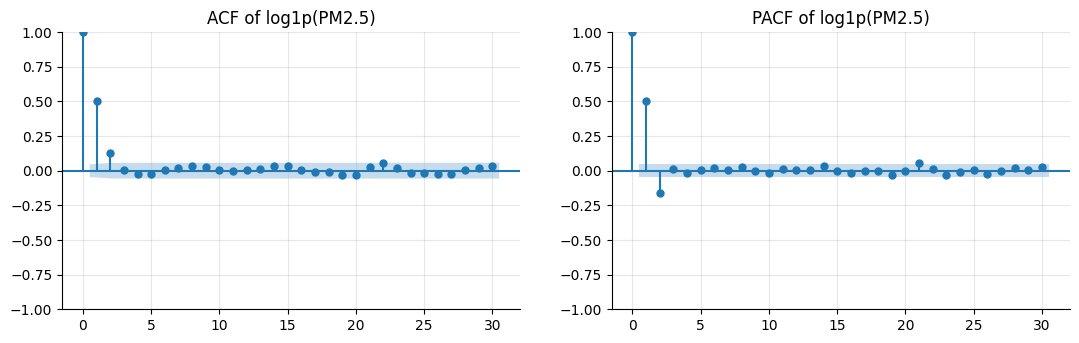

ACF  lags 1-5 : [ 0.5    0.128  0.005 -0.026 -0.02 ] | lag 7: 0.016 | lag 30: 0.035
PACF lags 1-5 : [ 0.5   -0.162  0.016 -0.02   0.003]
Lags with |PACF| > 0.1: [1, 2]


In [8]:
# A4.1: ACF / PACF of the target up to lag 30
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(y_target, lags=30, ax=axes[0]); plot_pacf(y_target, lags=30, ax=axes[1], method="ywm")
axes[0].set_title("ACF of log1p(PM2.5)"); axes[1].set_title("PACF of log1p(PM2.5)"); plt.show()
from statsmodels.tsa.stattools import acf, pacf
a, p = acf(y_target, nlags=30), pacf(y_target, nlags=30, method="ywm")
print("ACF  lags 1-5 :", np.round(a[1:6], 3), "| lag 7:", round(a[7], 3), "| lag 30:", round(a[30], 3))
print("PACF lags 1-5 :", np.round(p[1:6], 3))
print("Lags with |PACF| > 0.1:", [i for i in range(1, 31) if abs(p[i]) > 0.1])

Spearman correlation with TOMORROW's PM2.5:
PM2.5 (today)    0.499
Iws             -0.369
Ir              -0.129
DEWP             0.109
Is               0.035
PRES             0.021
TEMP            -0.001

Mean next-day PM2.5 by today's wind direction:
       mean  median  count
cbwd                      
cv    149.0   121.2    218
SE    109.3    97.9    801
NW     73.4    49.5    711
NE     70.9    53.5     95


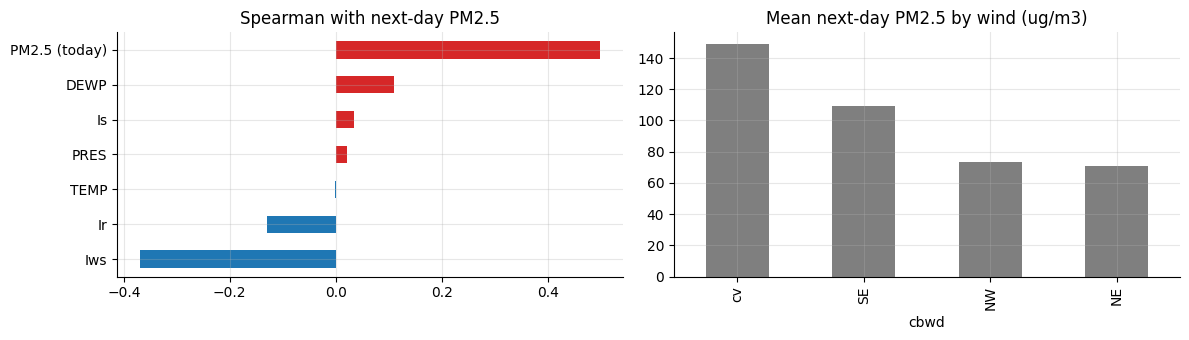

In [9]:
# A4.2 / A4.3: next-day PM2.5 vs today's weather
tmp = daily_clean.copy()
tmp["next_pm"] = tmp["pm2.5"].shift(-1)
tmp = tmp.dropna(subset=["next_pm"])
cors = {c: spearmanr(tmp[c], tmp["next_pm"])[0] for c in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]}
cors["PM2.5 (today)"] = spearmanr(tmp["pm2.5"], tmp["next_pm"])[0]
cors = pd.Series(cors).sort_values(key=np.abs, ascending=False)
print("Spearman correlation with TOMORROW's PM2.5:"); print(cors.round(3).to_string())

by_wind = tmp.groupby("cbwd")["next_pm"].agg(["mean", "median", "count"]).round(1).sort_values("mean", ascending=False)
print("\nMean next-day PM2.5 by today's wind direction:"); print(by_wind.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
cors.sort_values().plot.barh(ax=axes[0], color=["tab:red" if x > 0 else "tab:blue" for x in cors.sort_values()])
axes[0].set_title("Spearman with next-day PM2.5")
by_wind["mean"].plot.bar(ax=axes[1], color="tab:gray"); axes[1].set_title("Mean next-day PM2.5 by wind (ug/m3)")
plt.tight_layout(); plt.show()

**A4 — Your sanity prior:**

| Rank | Input | Expected sign | Reason |
|---|---|---|---|
| 1 | `pm_lag_1` (today's PM2.5) | + | ACF at lag 1 is 0.50 and Spearman with tomorrow's PM2.5 is 0.499: pollution persists. |
| 2 | `Iws_lag_1` (wind speed) | − | Spearman −0.369, the strongest weather correlation: strong wind flushes pollution out. |
| 3 | Wind direction (`cbwd_NW` −, `cbwd_SE` / `cbwd_cv` +) | − for NW, + for SE and calm | Mean next-day PM2.5 is 73.4 after NW, 70.9 after NE, 109.3 after SE and 149.0 µg/m³ after calm/variable wind. |
| 4 | `DEWP_lag_1` / `Ir_lag_1` (humidity, rain) | + for dew point, − for rain hours | Spearman +0.109 for dew point (humid stagnant air) and −0.129 for rain hours (wet removal). |
| 5 | `pm_lag_2` | − | PACF at lag 2 is −0.162 (ACF is +0.128): given yesterday, a higher day-before value signals decay. Heating season (+) is the next candidate. |

---
# Part B: Feature engineering and forecasters

### B1
Write `make_features(df) -> pd.DataFrame` that creates, for each day *t*, **only information available at the end of day t − 1**:

| Group | Features to create |
|---|---|
| PM2.5 recent lags | `pm_lag_1` … `pm_lag_3` |
| PM2.5 older lags | `pm_lag_4` … `pm_lag_7` |
| PM2.5 rolling stats | `pm_roll_mean_3`, `pm_roll_mean_7`, `pm_roll_std_7` |
| Weather, yesterday | `DEWP_lag_1`, `TEMP_lag_1`, `PRES_lag_1`, `Iws_lag_1`, `Is_lag_1`, `Ir_lag_1` |
| Weather change | `PRES_diff_1` (= PRES at t−1 minus t−2), `DEWP_diff_1` |
| Wind direction | one-hot of `cbwd` at t − 1 (4 columns) |
| Calendar | `doy_sin`, `doy_cos`, `is_heating_season` (15 Nov – 15 Mar), `dow` |

Store the groups in a dict `FEATURE_GROUPS`. Then write the leakage test: overwrite every raw value on one test day with random numbers, rebuild the features, and `assert` that the feature row for that same day is unchanged.

In [10]:
WIND_CATS = ["NW", "NE", "SE", "cv"]

def make_features(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    pm = df["pm2.5"]
    # PM2.5 lags 1..7 (value at day t-k is available at the end of day t-1 for k >= 1)
    for k in range(1, 8):
        X[f"pm_lag_{k}"] = pm.shift(k)
    # rolling stats computed on pm.shift(1): the window ends at t-1
    p1 = pm.shift(1)
    X["pm_roll_mean_3"] = p1.rolling(3).mean()
    X["pm_roll_mean_7"] = p1.rolling(7).mean()
    X["pm_roll_std_7"]  = p1.rolling(7).std()
    # yesterday's weather
    for c in ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]:
        X[f"{c}_lag_1"] = df[c].shift(1)
    # weather change: value at t-1 minus value at t-2
    X["PRES_diff_1"] = df["PRES"].shift(1) - df["PRES"].shift(2)
    X["DEWP_diff_1"] = df["DEWP"].shift(1) - df["DEWP"].shift(2)
    # one-hot wind direction at t-1 (fixed category list, so columns never depend on the data)
    w1 = df["cbwd"].shift(1)
    for cat in WIND_CATS:
        X[f"cbwd_{cat}"] = (w1 == cat).astype(int).where(w1.notna())
    # calendar features are known in advance, so day t itself is fine
    doy = df.index.dayofyear
    X["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    X["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    md = df.index.month * 100 + df.index.day                       # e.g. 1115 = 15 Nov
    X["is_heating_season"] = ((md >= 1115) | (md <= 315)).astype(int)
    X["dow"] = df.index.dayofweek
    # Target (transform it if USE_LOG_TARGET)
    X["target"] = np.log1p(pm) if USE_LOG_TARGET else pm
    return X.dropna()

FEATURE_GROUPS = {
    "PM recent lags (1-3)": ["pm_lag_1", "pm_lag_2", "pm_lag_3"],
    "PM older lags (4-7)":  ["pm_lag_4", "pm_lag_5", "pm_lag_6", "pm_lag_7"],
    "PM rolling stats":     ["pm_roll_mean_3", "pm_roll_mean_7", "pm_roll_std_7"],
    "Weather yesterday":    ["DEWP_lag_1", "TEMP_lag_1", "PRES_lag_1", "Iws_lag_1", "Is_lag_1", "Ir_lag_1"],
    "Weather change":       ["PRES_diff_1", "DEWP_diff_1"],
    "Wind direction":       [f"cbwd_{c}" for c in WIND_CATS],
    "Calendar":             ["doy_sin", "doy_cos", "is_heating_season", "dow"],
}

data = make_features(daily_clean)
feature_names = [c for c in data.columns if c != "target"]
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(feature_names), "groups must cover all features exactly once"
print(f"{len(data)} samples x {len(feature_names)} features | first sample: {data.index[0].date()} | last: {data.index[-1].date()}")

1819 samples x 26 features | first sample: 2010-01-08 | last: 2014-12-31


In [11]:
# B1 leakage test: corrupt EVERY raw value on one test day, rebuild, and check that day's feature row is unchanged.
test_day = pd.Timestamp("2014-06-15")
corrupted = daily_clean.copy()
rs = np.random.default_rng(0)
num_cols = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
corrupted[num_cols] = corrupted[num_cols].astype(float)      # Is / Ir are integer columns
corrupted.loc[test_day, num_cols] = rs.uniform(500, 1000, size=len(num_cols))
corrupted.loc[test_day, "cbwd"] = "SE" if daily_clean.loc[test_day, "cbwd"] != "SE" else "NW"

feats_clean, feats_corr = make_features(daily_clean), make_features(corrupted)
assert feats_corr.loc[test_day, feature_names].equals(feats_clean.loc[test_day, feature_names]), "LEAKAGE: day t raw values reach day t features"
# sanity check that the test has teeth: the NEXT day's features must change, and only the target of day t changes
nxt = test_day + pd.Timedelta(days=1)
assert not feats_corr.loc[nxt, feature_names].equals(feats_clean.loc[nxt, feature_names])
assert feats_corr.loc[test_day, "target"] != feats_clean.loc[test_day, "target"]
print("Leakage test passed")

Leakage test passed


### B2
Apply the fixed split. Print the date range and number of rows of train, validation and test.

In [12]:
# B2: fixed chronological split
train = data.loc["2010":"2012"]
val   = data.loc["2013"]
test  = data.loc["2014"]
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {d.index[0].date()} -> {d.index[-1].date()} | {len(d):4d} rows")
X_train, y_train = train[feature_names], train["target"]
X_val,   y_val   = val[feature_names],   val["target"]
X_test,  y_test  = test[feature_names],  test["target"]

def to_ugm3(y):
    """Back-transform model-space values to ug/m3."""
    y = np.asarray(y, dtype=float)
    return np.clip(np.expm1(y) if USE_LOG_TARGET else y, 0, None)

y_test_ug = to_ugm3(y_test)           # actual 2014 PM2.5 in ug/m3

train: 2010-01-08 -> 2012-12-31 | 1089 rows
val  : 2013-01-01 -> 2013-12-31 |  365 rows
test : 2014-01-01 -> 2014-12-31 |  365 rows


### B3
Fit and report test **MAE and RMSE in µg/m³** (even if you model the log target) for:
- (a) persistence: tomorrow = today,
- (b) 7-day mean,
- (c) a LightGBM regressor with early stopping on 2013.

Present the results in one table.

In [13]:
# B3
LGB_PARAMS = dict(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1,
                  deterministic=True, force_row_wise=True, n_jobs=1)
lgbm = lgb.LGBMRegressor(**LGB_PARAMS)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
print("best iteration:", lgbm.best_iteration_)
pred_lgbm_ug = to_ugm3(lgbm.predict(X_test))

results = pd.DataFrame({
    "Persistence": metrics(y_test_ug, X_test["pm_lag_1"].values),
    "7-day mean":  metrics(y_test_ug, X_test["pm_roll_mean_7"].values),
    "LightGBM":    metrics(y_test_ug, pred_lgbm_ug),
}).T.round(2)
results

best iteration: 107


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,44.98,67.19


**B3 — Your answer:**

LightGBM (early-stopped at 107 trees on 2013) reaches a test MAE of 44.98 µg/m³ and RMSE of 67.19, against 52.75 / 75.71 for persistence and 60.59 / 82.76 for the 7-day mean. That is a 14.7% MAE and 11.3% RMSE improvement over persistence. The 7-day mean is the worst baseline because PM2.5 changes sharply from one day to the next (lag-1 autocorrelation only 0.50), so averaging a week smears out the most useful, most recent information. Even the best model is wrong by about 45 µg/m³ on a series with mean 98, which shows how much of the next-day variation is driven by weather that arrives *after* the forecast is issued.

### B4 — the leakage experiment
Train a second LightGBM, `lgbm_oracle`, that additionally receives **day t's** weather (`DEWP`, `PRES`, `Iws`, `cbwd` at *t*). This simulates having a perfect weather forecast. Report its test MAE. In 3–4 sentences, explain when using such features is legitimate in a real system and when it is leakage. You will explain both models in Part C.

In [14]:
# B4: oracle model that also sees day t's weather (a "perfect weather forecast")
def add_oracle(df_clean, feats):
    o = feats.copy()
    for c in ["DEWP", "PRES", "Iws"]:
        o[f"{c}_t"] = df_clean[c].reindex(o.index)
    for cat in WIND_CATS:
        o[f"cbwd_t_{cat}"] = (df_clean["cbwd"].reindex(o.index) == cat).astype(int)
    return o

ORACLE_COLS = ["DEWP_t", "PRES_t", "Iws_t"] + [f"cbwd_t_{c}" for c in WIND_CATS]
data_o = add_oracle(daily_clean, data)
feature_names_o = feature_names + ORACLE_COLS
tr_o, va_o, te_o = data_o.loc["2010":"2012"], data_o.loc["2013"], data_o.loc["2014"]

lgbm_oracle = lgb.LGBMRegressor(**LGB_PARAMS)
lgbm_oracle.fit(tr_o[feature_names_o], tr_o["target"], eval_set=[(va_o[feature_names_o], va_o["target"])],
                callbacks=[lgb.early_stopping(100, verbose=False)])
pred_oracle_ug = to_ugm3(lgbm_oracle.predict(te_o[feature_names_o]))
results.loc["LightGBM oracle (sees day-t weather)"] = pd.Series(metrics(y_test_ug, pred_oracle_ug))
print("best iteration (oracle):", lgbm_oracle.best_iteration_)
results.round(2)

best iteration (oracle): 604


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,44.98,67.19
LightGBM oracle (sees day-t weather),30.10,42.36


**B4 — Your answer:**

The oracle model that also sees day *t*'s DEWP, PRES, Iws and wind direction reaches a test MAE of 30.10 µg/m³ (RMSE 42.36), a 33% reduction from the honest model's 44.98. Such features are **legitimate** only when they would truly be available at forecast time, i.e. when they are *forecasts* from a weather model issued before the PM2.5 forecast, and when the model is trained and evaluated on those forecast values with their errors. They are **leakage** when observed day-*t* weather is used, because the real system does not have it at issue time and the reported skill would never be achieved in production. The 14.9 µg/m³ gain is therefore an upper bound on what a weather-forecast input could add.

---
# Part C: SHAP
Use `shap.TreeExplainer` on the LightGBM from B3 unless told otherwise. If you model the log target, state clearly that SHAP values are in log units.

### C1
Compute SHAP values for the 2014 test set. Verify the **efficiency** property numerically: report the maximum absolute gap between base value + Σφ and the model output. Report the base value and translate it into µg/m³.

In [15]:
# C1
tree_explainer = shap.TreeExplainer(lgbm)
shap_exp = tree_explainer(X_test)                      # shap.Explanation: values (n, p), base_values (n,), data (n, p)
raw_out = lgbm.predict(X_test)                         # model output (log1p units when USE_LOG_TARGET)
recon = shap_exp.base_values + shap_exp.values.sum(1)
gap = np.abs(recon - raw_out).max()
base = float(np.mean(shap_exp.base_values))
unit = "log1p(ug/m3)" if USE_LOG_TARGET else "ug/m3"
print(f"SHAP values are in {unit}")
print(f"Efficiency check: max |base + sum(phi) - f(x)| = {gap:.2e}   (n = {len(X_test)} test days)")
print(f"Base value = {base:.4f} {unit}  ->  {to_ugm3(base):.1f} ug/m3 (expm1)")
print(f"Mean training target = {y_train.mean():.4f} -> {to_ugm3(y_train.mean()):.1f} ug/m3 | mean 2014 forecast (model space) = {raw_out.mean():.4f}")

SHAP values are in log1p(ug/m3)
Efficiency check: max |base + sum(phi) - f(x)| = 1.42e-14   (n = 365 test days)
Base value = 4.2864 log1p(ug/m3)  ->  71.7 ug/m3 (expm1)
Mean training target = 4.2864 -> 71.7 ug/m3 | mean 2014 forecast (model space) = 4.3474


**C1 — Your answer:**

The SHAP values are in log1p(µg/m³). The efficiency property holds to machine precision: the maximum absolute gap between base value + Σφ and the model output over the 365 test days is 1.42e-14 (TreeExplainer is exact). The base value is 4.2864, identical to the mean training target, and corresponds to 71.7 µg/m³ after `expm1`. The mean 2014 model output is 4.347, slightly above the base value, so on average 2014 forecasts sit a little above the training baseline. Note that only the log-scale decomposition is additive; converting individual φ to µg/m³ depends on the level it is added to.

### C2
Produce the global **bar** plot and **beeswarm** plot. Compare the top five features with your sanity prior from A4. For each weather feature in the top ten, state whether its colour pattern (direction) matches the physics in the domain hints. Identify one feature whose effect is *conditional*, like `lag_2` in the lecture, and explain it.

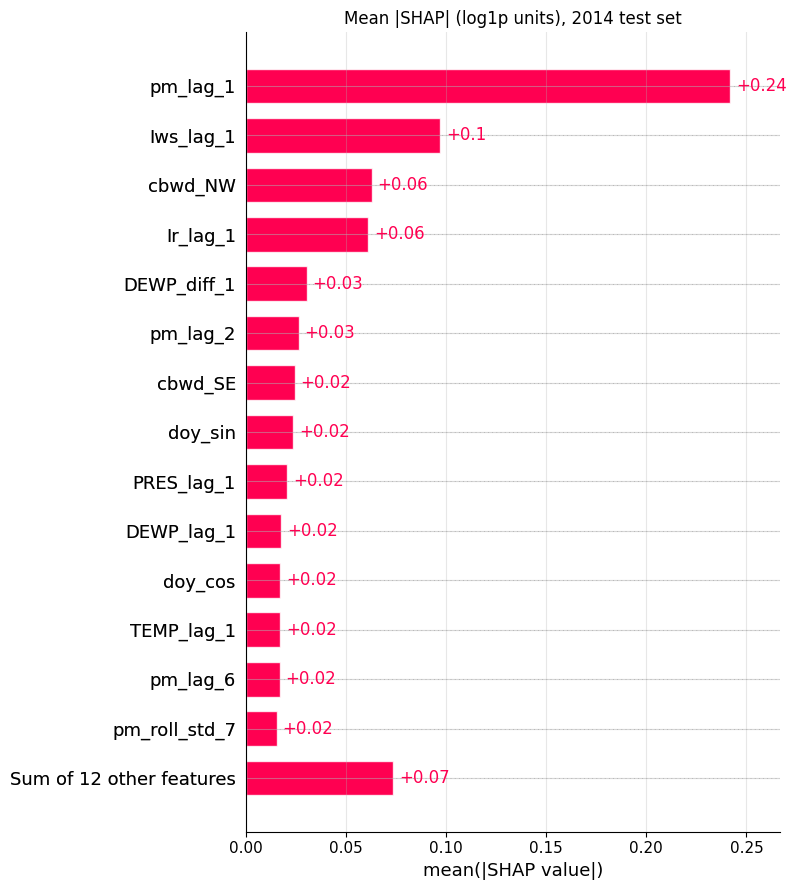

pm_lag_1       0.2420
Iws_lag_1      0.0971
cbwd_NW        0.0629
Ir_lag_1       0.0612
DEWP_diff_1    0.0305
pm_lag_2       0.0267
cbwd_SE        0.0246
doy_sin        0.0238
PRES_lag_1     0.0208
DEWP_lag_1     0.0178
doy_cos        0.0173
TEMP_lag_1     0.0172


In [16]:
# C2: global bar plot
shap.plots.bar(shap_exp, max_display=15, show=False)
plt.title("Mean |SHAP| (log1p units), 2014 test set"); plt.tight_layout(); plt.show()
imp = pd.Series(np.abs(shap_exp.values).mean(0), index=feature_names).sort_values(ascending=False)
print(imp.head(12).round(4).to_string())

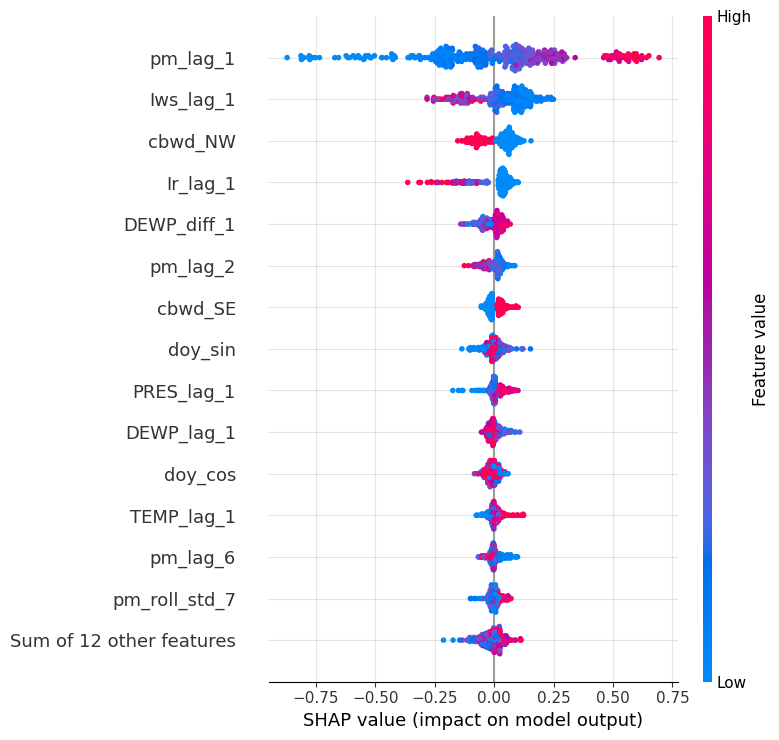

Spearman(feature value, SHAP) for the top 10 features:
pm_lag_1       0.97
Iws_lag_1     -0.88
cbwd_NW       -0.82
Ir_lag_1      -0.69
DEWP_diff_1    0.85
pm_lag_2      -0.77
cbwd_SE        0.86
doy_sin       -0.01
PRES_lag_1     0.70
DEWP_lag_1    -0.52

Spearman(pm_lag_2, tomorrow's PM2.5) on test: 0.062 | Spearman(pm_lag_1, pm_lag_2): 0.482
Mean SHAP of pm_lag_2 by (pm_lag_1 level x pm_lag_2 level):
pm_lag_2    lag_2 high  lag_2 low
pm_lag_1                         
lag_1 high      -0.016      0.022
lag_1 low       -0.024      0.022


In [17]:
# C2: beeswarm plot
shap.plots.beeswarm(shap_exp, max_display=15, show=False)
plt.tight_layout(); plt.show()
# direction of each top feature: Spearman between feature value and its SHAP value
dirn = {f: spearmanr(X_test[f], shap_exp.values[:, feature_names.index(f)])[0] for f in imp.head(10).index}
print("Spearman(feature value, SHAP) for the top 10 features:")
print(pd.Series(dirn).round(2).to_string())

# conditional effect: pm_lag_2 has a POSITIVE raw correlation with tomorrow's PM but a NEGATIVE SHAP slope
j2 = feature_names.index("pm_lag_2")
print("\nSpearman(pm_lag_2, tomorrow's PM2.5) on test:", round(spearmanr(X_test["pm_lag_2"], y_test)[0], 3),
      "| Spearman(pm_lag_1, pm_lag_2):", round(spearmanr(X_test["pm_lag_1"], X_test["pm_lag_2"])[0], 3))
hi1 = X_test["pm_lag_1"] > X_test["pm_lag_1"].median(); hi2 = X_test["pm_lag_2"] > X_test["pm_lag_2"].median()
ct = pd.DataFrame({"phi": shap_exp.values[:, j2], "pm_lag_1": np.where(hi1, "lag_1 high", "lag_1 low"), "pm_lag_2": np.where(hi2, "lag_2 high", "lag_2 low")})
print("Mean SHAP of pm_lag_2 by (pm_lag_1 level x pm_lag_2 level):"); print(ct.pivot_table(index="pm_lag_1", columns="pm_lag_2", values="phi", aggfunc="mean").round(3).to_string())

**C2 — Your answer:**

The top five by mean |SHAP| are `pm_lag_1` (0.242), `Iws_lag_1` (0.097), `cbwd_NW` (0.063), `Ir_lag_1` (0.061) and `DEWP_diff_1` (0.031). Ranks 1–3 match my prior exactly, and rain hours also appear as predicted; however `DEWP_lag_1` is only 10th (0.018) and `pm_lag_2` 6th (0.027), because humidity is carried by `DEWP_diff_1`. The weather directions match the physics: wind speed (Spearman between feature value and SHAP −0.88), NW wind (−0.82), rain hours (−0.69) lower the forecast, while SE wind (+0.86), high pressure (`PRES_lag_1` +0.70) and rising dew point (`DEWP_diff_1` +0.85) raise it. The one mismatch is `DEWP_lag_1` (−0.52): once the change in humidity and the PM history are known, the dew-point *level* gets negative credit, contradicting the simple hint. The conditional feature is `pm_lag_2`: its raw correlation with tomorrow's PM2.5 is +0.06, but its SHAP slope is negative (−0.77), matching the PACF of −0.162 at lag 2; it acts as a correction to `pm_lag_1` (a high value two days ago means the episode is already decaying).

### C3
Choose three test days:
1. the most polluted **forecast**,
2. the day with the largest absolute **error**,
3. the day with the largest one-day **drop** in actual PM2.5 (a clean-air event).

Draw a waterfall plot for each. For the clean-air day: did the model anticipate the drop, and which inputs pushed it down? If it missed, what information was it lacking?

most polluted forecast   2014-10-11 | forecast   232.2 | actual   197.6 | yesterday   325.4 ug/m3
largest error            2014-01-16 | forecast   134.4 | actual   457.5 | yesterday   191.8 ug/m3
largest one-day drop     2014-02-27 | forecast   112.4 | actual    19.9 | yesterday   407.7 ug/m3


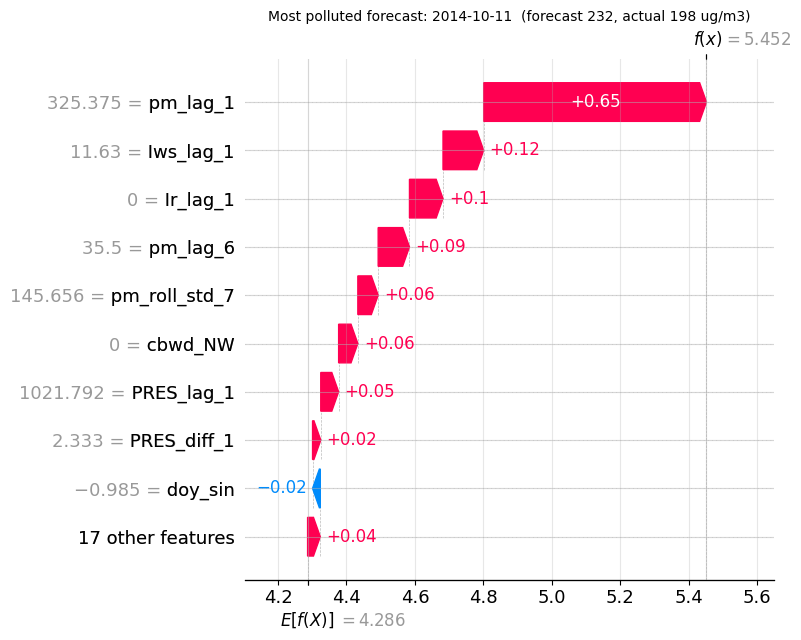

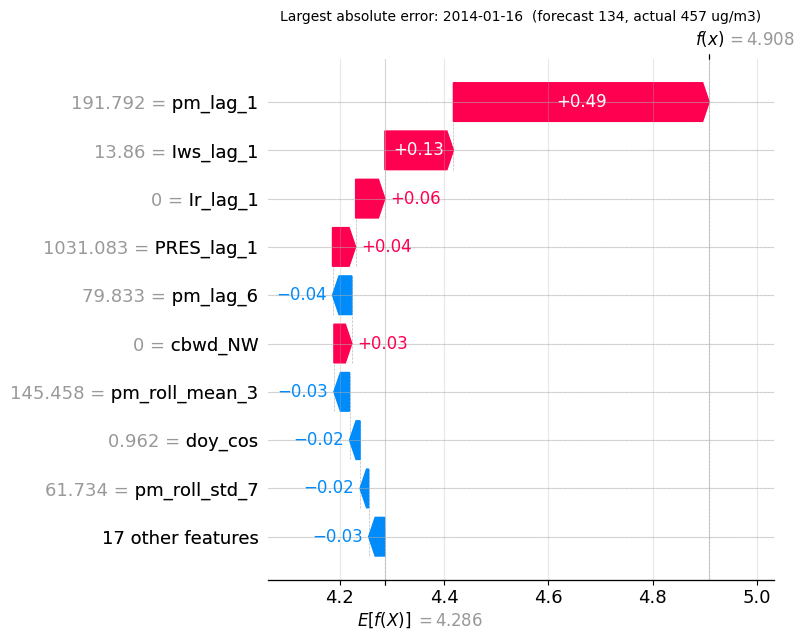

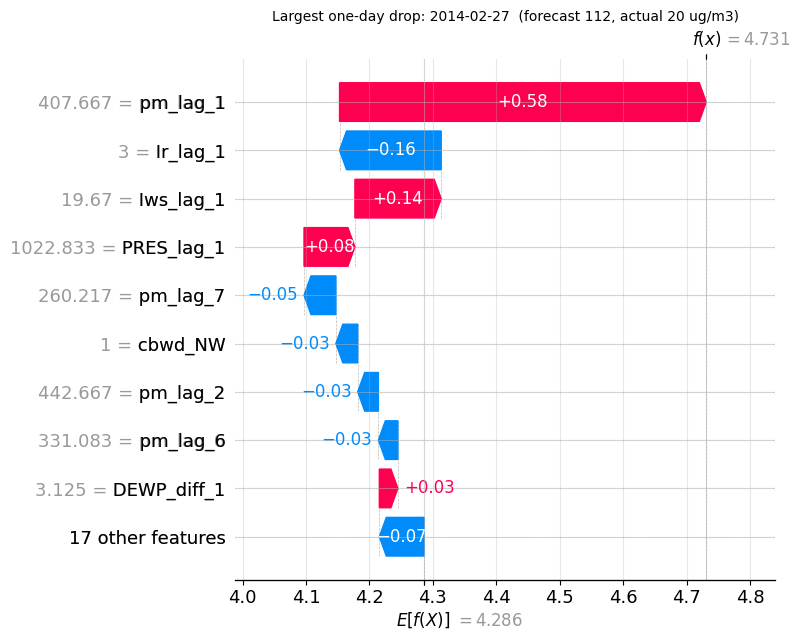


Clean-air day, strongest pushes (log units):
 Ir_lag_1     -0.160
pm_lag_7     -0.050
cbwd_NW      -0.034
PRES_lag_1    0.080
Iws_lag_1     0.136
pm_lag_1      0.578

Clean-air day, key raw inputs:
pm_lag_1          407.67
pm_lag_2          442.67
pm_roll_mean_3    400.65
Iws_lag_1          19.67
DEWP_lag_1         -1.17
PRES_diff_1        -3.21
cbwd_NW             1.00
cbwd_NE             0.00
cbwd_SE             0.00
cbwd_cv             0.00

Day t actual weather on the clean-air day (NOT visible to the model):
DEWP   -16.416667
PRES     1028.625
Iws         84.05
cbwd           NW


In [18]:
# C3
pos = lambda i: X_test.index.get_loc(i)
actual_ug = pd.Series(y_test_ug, index=X_test.index)
pred_ug   = pd.Series(pred_lgbm_ug, index=X_test.index)
err_ug    = (pred_ug - actual_ug)
drop_ug   = actual_ug - X_test["pm_lag_1"]            # actual change from yesterday to today

idx_high = pred_ug.idxmax()                           # most polluted forecast
idx_err  = err_ug.abs().idxmax()                      # largest absolute error
idx_drop = drop_ug.idxmin()                           # largest one-day drop in ACTUAL PM2.5
for name, i in [("most polluted forecast", idx_high), ("largest error", idx_err), ("largest one-day drop", idx_drop)]:
    print(f"{name:24s} {i.date()} | forecast {pred_ug[i]:7.1f} | actual {actual_ug[i]:7.1f} | yesterday {X_test.loc[i,'pm_lag_1']:7.1f} ug/m3")

for name, i in [("Most polluted forecast", idx_high), ("Largest absolute error", idx_err), ("Largest one-day drop", idx_drop)]:
    shap.plots.waterfall(shap_exp[pos(i)], max_display=10, show=False)
    plt.title(f"{name}: {i.date()}  (forecast {pred_ug[i]:.0f}, actual {actual_ug[i]:.0f} ug/m3)", fontsize=10)
    plt.tight_layout(); plt.show()

def top_contrib(i, k=6):
    s = pd.Series(shap_exp.values[pos(i)], index=feature_names)
    return pd.concat([s.sort_values().head(k // 2), s.sort_values().tail(k // 2)]).round(3)
print("\nClean-air day, strongest pushes (log units):\n", top_contrib(idx_drop).to_string())
print("\nClean-air day, key raw inputs:")
print(X_test.loc[idx_drop, ["pm_lag_1", "pm_lag_2", "pm_roll_mean_3", "Iws_lag_1", "DEWP_lag_1", "PRES_diff_1", "cbwd_NW", "cbwd_NE", "cbwd_SE", "cbwd_cv"]].round(2).to_string())
print("\nDay t actual weather on the clean-air day (NOT visible to the model):")
print(daily_clean.loc[idx_drop, ["DEWP", "PRES", "Iws", "cbwd"]].to_string())

**C3 — Your answer:**

The three days are: most polluted forecast 2014-10-11 (forecast 232.2, actual 197.6 µg/m³), largest error 2014-01-16 (forecast 134.4, actual 457.5) and largest drop 2014-02-27 (forecast 112.4, actual 19.9, after 407.7 the day before). On 10-11 the model output is 1.17 log units above the base, of which yesterday's 325.4 µg/m³ contributes +0.651, light wind (11.6) +0.119 and no rain +0.098. On the clean-air day the model **partly anticipated** the drop (112 versus 408 the day before, i.e. about 295 of the 388 µg/m³ fall), pushed down by rain hours (`Ir_lag_1` −0.160), `pm_lag_7` (−0.050) and NW wind (−0.034) while `pm_lag_1` (+0.578) pulled up. It missed the rest because the cold front arrived on the target day itself (actual Iws 84.1, NW, DEWP −16.4, PRES 1028.6), and the model only sees yesterday's weather (Iws 19.7). The largest-error day is the mirror case: yesterday's low wind and 191.8 µg/m³ gave only 134, but the actual 457.5 followed further stagnation on day *t* that is not in the inputs.

### C4
Draw two dependence plots: `Iws_lag_1` coloured by the NW wind indicator, and `pm_lag_1` coloured by `DEWP_lag_1`. Describe the shape of each learned response curve (linear, saturating, threshold) and the interaction the colour reveals.

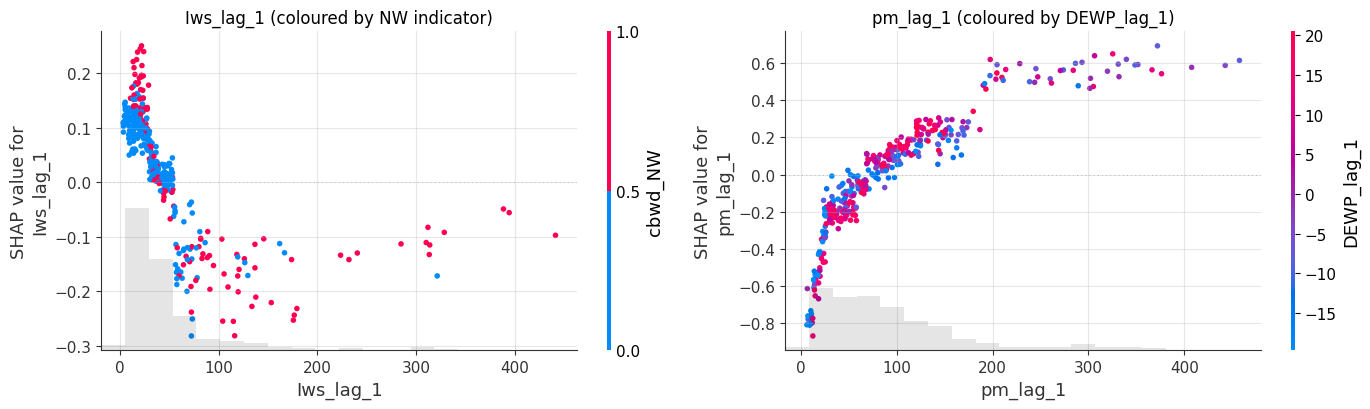

Iws_lag_1: mean SHAP by quantile bin of wind speed
x
(3.119, 15.554]    0.116
(15.554, 25.03]    0.128
(25.03, 39.784]    0.053
(39.784, 63.32]   -0.024
(63.32, 441.18]   -0.148

Iws_lag_1: mean SHAP by wind-speed bin x NW flag (the interaction):
                  mean        count    
NW                 0.0    1.0   0.0 1.0
bin                                    
(3.119, 15.554]  0.109  0.176    65   8
(15.554, 25.03]  0.104  0.168    46  28
(25.03, 39.784]  0.049  0.063    50  22
(39.784, 63.32] -0.021 -0.036    58  15
(63.32, 441.18] -0.134 -0.154    23  50

pm_lag_1: mean SHAP by quantile bin
x
(6.4159999999999995, 29.651]   -0.467
(29.651, 53.0]                 -0.171
(53.0, 77.667]                 -0.050
(77.667, 104.556]               0.079
(104.556, 151.028]              0.198
(151.028, 457.5]                0.448
pm_lag_1 (top 30%): corr(SHAP, DEWP_lag_1) = 0.168

pm_lag_1: mean SHAP by pm_lag_1 quartile x humidity (the interaction):
humid                         DEWP high  DE

In [19]:
# C4
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
shap.plots.scatter(shap_exp[:, "Iws_lag_1"], color=shap_exp[:, "cbwd_NW"], ax=axes[0], show=False)
axes[0].set_title("Iws_lag_1 (coloured by NW indicator)")
shap.plots.scatter(shap_exp[:, "pm_lag_1"], color=shap_exp[:, "DEWP_lag_1"], ax=axes[1], show=False)
axes[1].set_title("pm_lag_1 (coloured by DEWP_lag_1)")
plt.tight_layout(); plt.show()

# numbers to describe the curves
j = feature_names.index("Iws_lag_1"); k = feature_names.index("pm_lag_1")
iw = pd.DataFrame({"x": X_test["Iws_lag_1"], "phi": shap_exp.values[:, j], "NW": X_test["cbwd_NW"]})
print("Iws_lag_1: mean SHAP by quantile bin of wind speed")
print(iw.groupby(pd.qcut(iw["x"], 5, duplicates="drop"), observed=True)["phi"].mean().round(3).to_string())
iw["bin"] = pd.qcut(iw["x"], 5, duplicates="drop")
print("\nIws_lag_1: mean SHAP by wind-speed bin x NW flag (the interaction):")
print(iw.pivot_table(index="bin", columns="NW", values="phi", aggfunc=["mean", "count"], observed=True).round(3).to_string())
pm1 = pd.DataFrame({"x": X_test["pm_lag_1"], "phi": shap_exp.values[:, k], "dew": X_test["DEWP_lag_1"]})
print("\npm_lag_1: mean SHAP by quantile bin")
print(pm1.groupby(pd.qcut(pm1["x"], 6, duplicates="drop"), observed=True)["phi"].mean().round(3).to_string())
hi = pm1[pm1.x > pm1.x.quantile(0.7)]
print("pm_lag_1 (top 30%): corr(SHAP, DEWP_lag_1) =", round(spearmanr(hi["phi"], hi["dew"])[0], 3))
pm1["pbin"] = pd.qcut(pm1["x"], 4, duplicates="drop"); pm1["humid"] = np.where(pm1["dew"] > pm1["dew"].median(), "DEWP high", "DEWP low")
print("\npm_lag_1: mean SHAP by pm_lag_1 quartile x humidity (the interaction):")
print(pm1.pivot_table(index="pbin", columns="humid", values="phi", aggfunc="mean", observed=True).round(3).to_string())

**C4 — Your answer:**

The `Iws_lag_1` response is a **threshold-then-decline** curve, not a line: mean SHAP across wind-speed quintiles is +0.116, +0.128, +0.053, −0.024 and −0.148, i.e. flat and slightly positive up to about 25 and falling steadily beyond. The colour shows a modest interaction: with weak wind NW days have higher SHAP (+0.176 vs +0.109 in the lowest bin), and with the strongest wind NW is more negative (−0.154 vs −0.134), so NW makes the wind curve steeper, but the difference never exceeds about 0.07. The `pm_lag_1` response is monotone and S-shaped (mean SHAP −0.467 below 30 µg/m³, −0.050 around 55–78, +0.198 around 105–151 and +0.448 above 151), steepest in the middle and saturating in the tails. Humidity matters in the middle range (78–125 µg/m³: +0.142 for humid vs +0.076 for dry days) but not at the extremes (≤0.04 difference), and the rank correlation between SHAP and dew point among the top 30% of days is only 0.168.

### C5 — grouped and seasonal SHAP
Sum SHAP values within each group of `FEATURE_GROUPS`. Plot:
- (a) mean |grouped SHAP| as a bar chart,
- (b) a month × group heatmap of mean |grouped SHAP| for 2014.

Is the model mainly a persistence model or a weather model? Does reliance on weather change between the heating and non-heating seasons?

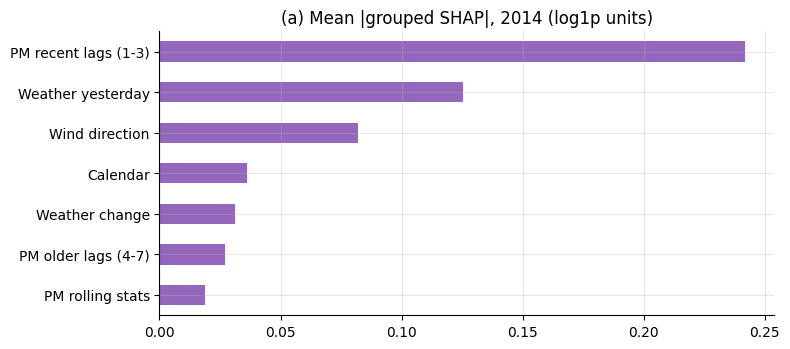

PM recent lags (1-3)    43.0
Weather yesterday       22.3
Wind direction          14.6
Calendar                 6.4
Weather change           5.6
PM older lags (4-7)      4.8
PM rolling stats         3.4 
(share of total mean |SHAP|, %)


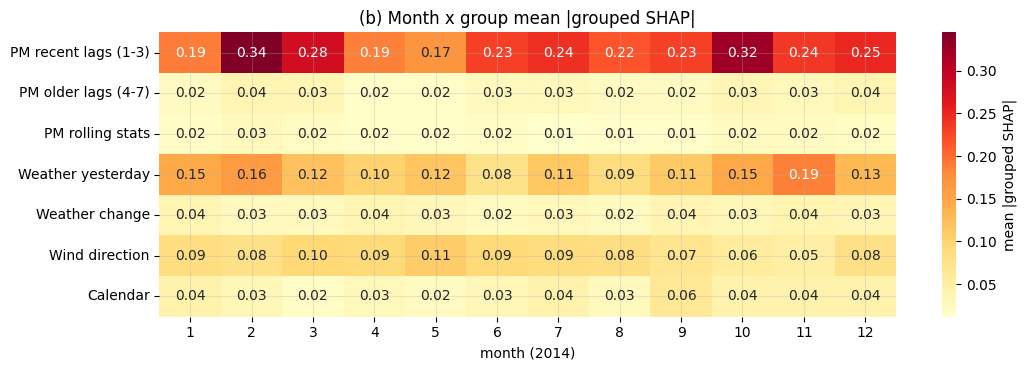


                                         heating (n=121)  non-heating (n=244)
weather groups (sum of mean|SHAP|)                 0.266                0.224
PM-history groups                                  0.310                0.277
weather share of (weather + PM-history)            0.462                0.447

Weather groups' share of total mean|SHAP| by month:
{1: 50, 2: 38, 3: 41, 4: 48, 5: 53, 6: 39, 7: 41, 8: 41, 9: 40, 10: 36, 11: 45, 12: 41}
Top-3 weather features, heating vs non-heating (mean |SHAP|):
  heating {'Iws_lag_1': 0.117, 'cbwd_NW': 0.061, 'Ir_lag_1': 0.043}
  non-heating {'Iws_lag_1': 0.087, 'Ir_lag_1': 0.07, 'cbwd_NW': 0.064}


In [20]:
# C5
def grouped(values, names=feature_names, groups=FEATURE_GROUPS, index=None):
    return pd.DataFrame({g: values[:, [names.index(f) for f in fs]].sum(1) for g, fs in groups.items()}, index=index)

group_shap = grouped(shap_exp.values, index=X_test.index)
gm = group_shap.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6)); gm.plot.barh(ax=ax, color="tab:purple")
ax.set_title("(a) Mean |grouped SHAP|, 2014 (log1p units)"); plt.tight_layout(); plt.show()
print((gm / gm.sum() * 100).round(1).sort_values(ascending=False).to_string(), "\n(share of total mean |SHAP|, %)")

heat = group_shap.abs().groupby(group_shap.index.month).mean().T
heat = heat.loc[list(FEATURE_GROUPS)]
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "mean |grouped SHAP|"})
ax.set_xlabel("month (2014)"); ax.set_title("(b) Month x group mean |grouped SHAP|"); plt.tight_layout(); plt.show()

heating = X_test["is_heating_season"].values == 1
wcols = ["Weather yesterday", "Weather change", "Wind direction"]
pcols = ["PM recent lags (1-3)", "PM older lags (4-7)", "PM rolling stats"]
cmp_tbl = pd.DataFrame({
    "heating (n=%d)" % heating.sum():       [group_shap.loc[heating, wcols].abs().sum(1).mean(),  group_shap.loc[heating, pcols].abs().sum(1).mean()],
    "non-heating (n=%d)" % (~heating).sum(): [group_shap.loc[~heating, wcols].abs().sum(1).mean(), group_shap.loc[~heating, pcols].abs().sum(1).mean()],
}, index=["weather groups (sum of mean|SHAP|)", "PM-history groups"]).round(3)
cmp_tbl.loc["weather share of (weather + PM-history)"] = (cmp_tbl.iloc[0] / (cmp_tbl.iloc[0] + cmp_tbl.iloc[1])).round(3)
print(); print(cmp_tbl.to_string())
wk = heat.loc[wcols].sum() / heat.sum()
print("\nWeather groups' share of total mean|SHAP| by month:"); print((100 * wk).round(0).astype(int).to_dict())
print("Top-3 weather features, heating vs non-heating (mean |SHAP|):")
for nm, msk in [("heating", heating), ("non-heating", ~heating)]:
    wf = [f for g in wcols for f in FEATURE_GROUPS[g]]
    print(" ", nm, pd.Series(np.abs(shap_exp.values[msk][:, [feature_names.index(f) for f in wf]]).mean(0), index=wf).sort_values(ascending=False).head(3).round(3).to_dict())

**C5 — Your answer:**

The grouped shares of total mean |SHAP| are PM recent lags 43.0%, weather yesterday 22.3%, wind direction 14.6%, calendar 6.4%, weather change 5.6%, PM older lags 4.8% and PM rolling stats 3.4%. PM history combined gives 51.2% and the three weather groups 42.5%, so the model is **mainly a persistence model with a large weather component** (a hybrid). Between seasons the *relative* reliance barely changes: weather is 46.2% of the weather-plus-history credit in the heating season (n = 121) and 44.7% outside it (n = 244), although absolute weather credit is larger in heating months (0.266 vs 0.224). What changes is the composition: `Iws_lag_1` matters more in heating season (0.117 vs 0.087) while rain hours matter more outside it (0.070 vs 0.043); across months the weather share ranges from 36% (October) to 53% (May).

### C6 — explaining the oracle
Repeat C5(a) for `lgbm_oracle` from B4. How does the importance of the PM2.5 lags change when the model can see day *t*'s weather? Explain what this shows about how correlated inputs share credit.

oracle efficiency gap: 0.0


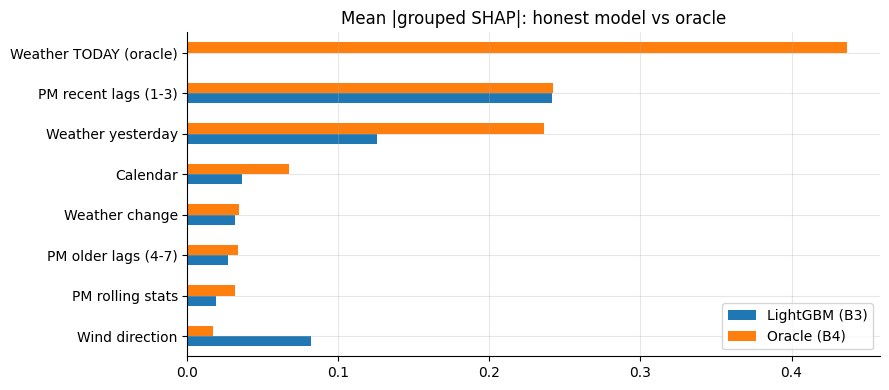

Mean |grouped SHAP| (absolute):
                        LightGBM (B3)  Oracle (B4)
Calendar                        0.036        0.067
PM older lags (4-7)             0.027        0.033
PM recent lags (1-3)            0.242        0.242
PM rolling stats                0.019        0.031
Weather TODAY (oracle)          0.000        0.437
Weather change                  0.031        0.034
Weather yesterday               0.125        0.236
Wind direction                  0.082        0.017
Share of total mean|SHAP| (%):
                        LightGBM (B3)  Oracle (B4)
Calendar                          6.4          6.1
PM older lags (4-7)               4.8          3.0
PM recent lags (1-3)             43.0         22.1
PM rolling stats                  3.4          2.9
Weather TODAY (oracle)            0.0         39.8
Weather change                    5.6          3.1
Weather yesterday                22.3         21.5
Wind direction                   14.6          1.5

PM-history groups 

In [21]:
# C6: explain the oracle model
GROUPS_O = dict(FEATURE_GROUPS); GROUPS_O["Weather TODAY (oracle)"] = ORACLE_COLS
exp_o = shap.TreeExplainer(lgbm_oracle)(te_o[feature_names_o])
print("oracle efficiency gap:", np.abs(exp_o.base_values + exp_o.values.sum(1) - lgbm_oracle.predict(te_o[feature_names_o])).max().round(8))
group_shap_o = grouped(exp_o.values, names=feature_names_o, groups=GROUPS_O, index=te_o.index)
cmp = pd.DataFrame({"LightGBM (B3)": group_shap.abs().mean(), "Oracle (B4)": group_shap_o.abs().mean()}).fillna(0)
fig, ax = plt.subplots(figsize=(9, 4)); cmp.sort_values("Oracle (B4)").plot.barh(ax=ax)
ax.set_title("Mean |grouped SHAP|: honest model vs oracle"); plt.tight_layout(); plt.show()
print("Mean |grouped SHAP| (absolute):"); print(cmp.round(3).to_string())
sh = (cmp / cmp.sum() * 100).round(1); print("Share of total mean|SHAP| (%):"); print(sh.to_string())
lags = ["PM recent lags (1-3)", "PM older lags (4-7)", "PM rolling stats"]
print("\nPM-history groups combined:  B3 =", sh.loc[lags, "LightGBM (B3)"].sum().round(1), "%  | oracle =", sh.loc[lags, "Oracle (B4)"].sum().round(1), "%")
print("Mean |SHAP| of pm_lag_1: B3 =", np.abs(shap_exp.values[:, feature_names.index("pm_lag_1")]).mean().round(3),
      "| oracle =", np.abs(exp_o.values[:, feature_names_o.index("pm_lag_1")]).mean().round(3))
print("Weather-yesterday group: B3 =", cmp.loc["Weather yesterday", "LightGBM (B3)"].round(3), "| oracle =", cmp.loc["Weather yesterday", "Oracle (B4)"].round(3))
print("Top oracle features:"); print(pd.Series(np.abs(exp_o.values).mean(0), index=feature_names_o).sort_values(ascending=False).head(6).round(3).to_string())

**C6 — Your answer:**

When the model sees day *t*'s weather, the PM-history groups fall from 51.2% to 28.0% of the credit (recent lags 43.0% → 22.1%), while the new "weather today" group takes 39.8% (mean |SHAP| 0.437; `DEWP_t` 0.199, `Iws_t` 0.166). The lags did not become less useful in absolute terms: `pm_lag_1` has mean |SHAP| of 0.242 in the honest model and 0.243 in the oracle, so the share falls only because the total credit grows. The clearest transfer is the yesterday-wind-direction group, which collapses from 0.082 (14.6%) to 0.017 (1.5%) because today's wind speed and direction (`cbwd_t_NW` 0.093) are the variables it was only a proxy for. This shows that correlated inputs share credit, so a small SHAP value means "redundant given what else is present", not "irrelevant", and the importance ranking depends on which proxies are in the model.

---
# Part D: LIME

In [22]:
def predict_fn(arr):
    return lgbm.predict(pd.DataFrame(arr, columns=feature_names))

### D1
Explain the most polluted forecast and the clean-air day from C3 with `LimeTabularExplainer` (5,000 samples). Report the black-box forecast, LIME's surrogate prediction and the local R² for each. Which of the two explanations would you trust more, and why?

In [23]:
# D1
CAT_FREE = dict(discretize_continuous=False)        # non-discretised variant (weights apply to standardised features)
def new_lime(seed=SEED):
    return LimeTabularExplainer(X_train.values, feature_names=feature_names, mode="regression",
                                random_state=seed, **CAT_FREE)
lime_explainer = new_lime()

def lime_explain(x_row, n=5000, seed=SEED, explainer=None):
    ex = explainer or new_lime(seed)
    return ex.explain_instance(x_row, predict_fn, num_features=len(feature_names), num_samples=n)

def lime_contrib(exp, x_row, explainer):
    """LIME contribution = weight x standardised value (non-discretised variant)."""
    w = dict(exp.as_map()[1])                       # regression: label 1 holds the weights (label 0 is the negated copy)
    wv = np.array([w[j] for j in range(len(feature_names))])
    xs = (x_row - explainer.scaler.mean_) / explainer.scaler.scale_
    return wv * xs, exp.intercept[1]

rows = []
for name, i in [("Most polluted forecast", idx_high), ("Clean-air day", idx_drop)]:
    x = X_test.loc[i].values.astype(float)
    exp = lime_explain(x, 5000, SEED, lime_explainer)
    bb = predict_fn(x.reshape(1, -1))[0]
    c, icpt = lime_contrib(exp, x, lime_explainer)
    assert abs(icpt + c.sum() - exp.local_pred[0]) < 1e-6
    rows.append({"day": i.date(), "case": name, "black-box (log)": bb, "LIME (log)": exp.local_pred[0],
                 "black-box ug/m3": to_ugm3(bb), "LIME ug/m3": to_ugm3(exp.local_pred[0]), "local R2": exp.score})
    s = pd.Series(c, index=feature_names); s = s.reindex(s.abs().sort_values(ascending=False).index)
    print(f"\n{name} ({i.date()}), top LIME contributions (log units):"); print(s.head(6).round(3).to_string())
    shp = pd.Series(shap_exp.values[pos(i)], index=feature_names)
    print("SHAP top-6 for comparison:", list(shp.reindex(shp.abs().sort_values(ascending=False).index).head(6).index))
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
lime_tbl = pd.DataFrame(rows).round(3); lime_tbl


Most polluted forecast (2014-10-11), top LIME contributions (log units):
pm_lag_1          0.899
pm_lag_2         -0.109
Iws_lag_1         0.089
pm_roll_mean_3    0.048
Ir_lag_1          0.034
cbwd_NW           0.022
SHAP top-6 for comparison: ['pm_lag_1', 'Iws_lag_1', 'Ir_lag_1', 'pm_lag_6', 'pm_roll_std_7', 'cbwd_NW']

Clean-air day (2014-02-27), top LIME contributions (log units):
pm_lag_1          1.060
pm_lag_2         -0.210
Iws_lag_1         0.068
pm_roll_mean_7   -0.062
Ir_lag_1         -0.052
pm_roll_mean_3   -0.042
SHAP top-6 for comparison: ['pm_lag_1', 'Ir_lag_1', 'Iws_lag_1', 'PRES_lag_1', 'pm_lag_7', 'cbwd_NW']


,day,case,black-box (log),LIME (log),black-box ug/m3,LIME ug/m3,local R2
0,2014-10-11,Most polluted forecast,5.452,5.136,232.151,169.041,0.724
1,2014-02-27,Clean-air day,4.731,4.759,112.395,115.609,0.737


**D1 — Your answer:**

For the most polluted forecast (2014-10-11) the black box gives 232.2 µg/m³ (5.452 in log units) while the LIME surrogate gives 169.0 (5.136), with local R² = 0.724. For the clean-air day (2014-02-27) the black box gives 112.4 (4.731) and LIME 115.6 (4.759), with R² = 0.737. I trust the **clean-air explanation more**: the surrogate reproduces the model within 3% there, whereas on the polluted day it underestimates by 27%, because the instance sits in the tail of the target where a single linear model fitted to neighbours around the training mean cannot follow the forest. The R² values are almost equal, so R² alone would not have revealed this; the local prediction gap does. In both cases `pm_lag_1` dominates LIME (0.899 and 1.060 log units), but LIME ranks `pm_lag_2` second whereas SHAP ranks `Iws_lag_1` and `Ir_lag_1` there.

### D2 — unrealistic neighbours
Generate LIME's perturbation samples for one instance (or reproduce LIME's sampling yourself) and count the fraction of neighbours that are **physically implausible**. Define implausible with at least two rules you justify, for example:
- `pm_lag_1` more than 3 × `pm_roll_mean_3` (impossible by construction),
- snow hours > 0 with `TEMP_lag_1` > 10 °C.

Explain why this matters more for time series than for ordinary tabular data.

In [24]:
# D2: how realistic are LIME's neighbours? (instance = most polluted forecast)
x0 = X_test.loc[idx_high].values.astype(float)
_inv = lime_explainer._LimeTabularExplainer__data_inverse                          # LIME's own perturbation sampler
try:    Z, _ = _inv(x0, 5000)
except TypeError: Z, _ = _inv(x0, 5000, "gaussian")                                # newer lime versions take a sampling method
Zdf = pd.DataFrame(Z, columns=feature_names)

rules = {
  "R1 pm_lag_1 > 3 x pm_roll_mean_3 (impossible by construction)": Zdf.pm_lag_1 > 3 * Zdf.pm_roll_mean_3 + 1e-9,
  "R2 negative PM, wind speed, snow or rain":    (Zdf[[f"pm_lag_{k}" for k in range(1, 8)] + ["pm_roll_mean_3", "pm_roll_mean_7", "pm_roll_std_7", "Iws_lag_1", "Is_lag_1", "Ir_lag_1"]] < 0).any(axis=1),
  "R3 snow hours > 0 while TEMP_lag_1 > 10 C":   (Zdf.Is_lag_1 > 0) & (Zdf.TEMP_lag_1 > 10),
  "R4 dew point > temperature + 2 C":              Zdf.DEWP_lag_1 > Zdf.TEMP_lag_1 + 2,
  "R5 one-hot wind not exactly one-hot":           ~np.isclose(Zdf[[f"cbwd_{c}" for c in WIND_CATS]].sum(1), 1.0) | ((Zdf[[f"cbwd_{c}" for c in WIND_CATS]] % 1) != 0).any(axis=1),
  "R6 7*mean7 != sum of 7 lags (+-1)":             (7 * Zdf.pm_roll_mean_7 - Zdf[[f"pm_lag_{k}" for k in range(1, 8)]].sum(1)).abs() > 1,
  "R7 is_heating_season not 0/1 or dow not integer 0-6": ~Zdf.is_heating_season.isin([0, 1]) | (Zdf.dow % 1 != 0) | (Zdf.dow < 0) | (Zdf.dow > 6),
}
tbl = pd.Series({k: v.mean() for k, v in rules.items()})
any_bad = pd.concat(rules, axis=1).any(axis=1).mean()
sem = pd.concat([rules[k] for k in list(rules)[:4] + [list(rules)[5]]], axis=1).any(axis=1).mean()   # physical/algebraic rules only
print((tbl * 100).round(1).to_string()); print(f"\nAny rule violated (all 7): {100*any_bad:.1f}% | any of the physical/algebraic rules R1-R4,R6: {100*sem:.1f}%")
# For reference: the same rules on REAL 2014 test days
real = X_test
real_bad = ((real.pm_lag_1 > 3 * real.pm_roll_mean_3 + 1e-9) | ((real.Is_lag_1 > 0) & (real.TEMP_lag_1 > 10)) | (real.DEWP_lag_1 > real.TEMP_lag_1 + 2)).mean()
print(f"Same R1/R3/R4 rules on the 2014 real days: {100*real_bad:.2f}% violated")

R1 pm_lag_1 > 3 x pm_roll_mean_3 (impossible by construction)     15.0
R2 negative PM, wind speed, snow or rain                          87.2
R3 snow hours > 0 while TEMP_lag_1 > 10 C                         33.1
R4 dew point > temperature + 2 C                                  25.2
R5 one-hot wind not exactly one-hot                              100.0
R6 7*mean7 != sum of 7 lags (+-1)                                 99.5
R7 is_heating_season not 0/1 or dow not integer 0-6              100.0

Any rule violated (all 7): 100.0% | any of the physical/algebraic rules R1-R4,R6: 99.9%
Same R1/R3/R4 rules on the 2014 real days: 0.00% violated


**D2 — Your answer:**

I drew LIME's own 5,000 perturbations around the most polluted forecast and tested them against rules. 15.0% have `pm_lag_1` > 3 × `pm_roll_mean_3` (impossible by construction), 87.2% contain a negative PM2.5, wind, snow or rain value, 33.1% have snow hours with TEMP > 10 °C, 25.2% have a dew point more than 2 °C above the temperature, and 99.5% break the identity that the 7-day mean times 7 equals the sum of the seven lags. The one-hot wind and binary calendar columns are never valid (100%) because they are sampled as Gaussians; even ignoring those two rules, 99.9% of neighbours violate at least one physical or algebraic rule, whereas none of the real 2014 days violates the R1, R3 and R4 rules (0.00%). This matters more for time series because the features are deterministic functions of one another (rolling means are built from lags, calendar features are linked), so independent sampling creates impossible histories where the model is simply extrapolating, and the surrogate is then fitted mostly on those.

### D3 — stability
Re-run LIME 15 times with different seeds, using **500** and **5,000** samples, on the same instance. Show a boxplot of the weights for the top eight features and a table of the coefficient of variation. List the features whose **sign** flips across seeds.

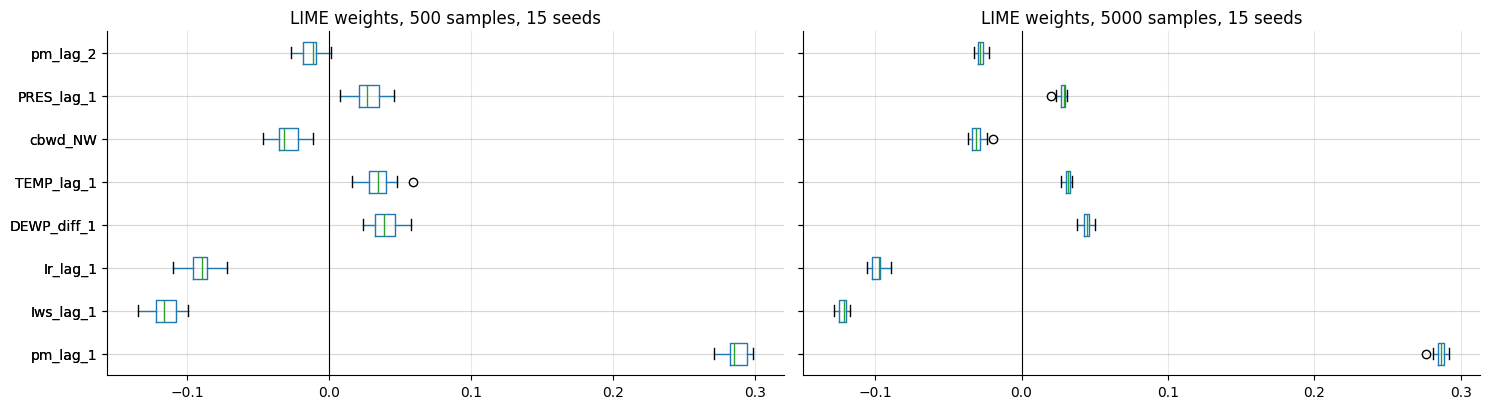

             CV (500)  CV (5000)
pm_lag_1         0.03       0.01
Iws_lag_1        0.09       0.03
Ir_lag_1         0.11       0.05
DEWP_diff_1      0.26       0.07
TEMP_lag_1       0.30       0.08
cbwd_NW          0.33       0.15
PRES_lag_1       0.37       0.10
pm_lag_2         0.64       0.11

Features whose sign flips across the 15 seeds (500 samples): ['pm_lag_2', 'pm_lag_4', 'pm_lag_5', 'pm_lag_6', 'pm_lag_7', 'pm_roll_std_7', 'DEWP_lag_1', 'Is_lag_1', 'cbwd_NE', 'cbwd_cv', 'doy_sin', 'doy_cos', 'is_heating_season']
   mean CV of top-8: 0.27 | sign flips inside top-8: ['pm_lag_2']

Features whose sign flips across the 15 seeds (5000 samples): ['pm_lag_3', 'pm_lag_4', 'pm_lag_5', 'pm_lag_7', 'pm_roll_mean_7', 'pm_roll_std_7', 'Is_lag_1', 'cbwd_NE', 'cbwd_cv', 'is_heating_season']
   mean CV of top-8: 0.08 | sign flips inside top-8: []

Stability of the top-8 ranking (mean pairwise Spearman of |weights| across seeds):
  500: 0.628
  5000: 0.907


In [25]:
# D3: stability across seeds
SEEDS = list(range(15))
inst = X_test.loc[idx_high].values.astype(float)
W_ = {}
for n in [500, 5000]:
    rows_ = []
    for s in SEEDS:
        ex = new_lime(s)
        e = ex.explain_instance(inst, predict_fn, num_features=len(feature_names), num_samples=n)
        w = dict(e.as_map()[1]); rows_.append([w[j] for j in range(len(feature_names))])
    W_[n] = pd.DataFrame(rows_, columns=feature_names)
top8 = W_[5000].abs().mean().sort_values(ascending=False).head(8).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, n in zip(axes, [500, 5000]):
    W_[n][top8].boxplot(ax=ax, vert=False); ax.axvline(0, color="k", lw=0.8); ax.set_title(f"LIME weights, {n} samples, 15 seeds")
plt.tight_layout(); plt.show()

cv = pd.DataFrame({f"CV (500)":  (W_[500][top8].std() / W_[500][top8].mean().abs()),
                   f"CV (5000)": (W_[5000][top8].std() / W_[5000][top8].mean().abs())}).round(2)
print(cv.to_string())
for n in [500, 5000]:
    flips = [f for f in feature_names if (W_[n][f] > 0).any() and (W_[n][f] < 0).any()]
    print(f"\nFeatures whose sign flips across the 15 seeds ({n} samples): {flips}")
    print("   mean CV of top-8:", np.round(cv[f'CV ({n})'].mean(), 2), "| sign flips inside top-8:", [f for f in flips if f in top8])
print("\nStability of the top-8 ranking (mean pairwise Spearman of |weights| across seeds):")
for n in [500, 5000]:
    A = W_[n].abs().values; r = [spearmanr(A[a], A[b])[0] for a in range(15) for b in range(a + 1, 15)]
    print(f"  {n}: {np.mean(r):.3f}")

**D3 — Your answer:**

With 5,000 samples the coefficient of variation of the top-8 weights averages 0.08 (from 0.01 for `pm_lag_1` to 0.15 for `cbwd_NW`); with 500 samples it averages 0.27 (from 0.03 to 0.64 for `pm_lag_2`). The mean pairwise Spearman correlation of |weights| across seeds rises from 0.628 to 0.907. At 500 samples 13 features flip sign across the 15 seeds (`pm_lag_2`, `pm_lag_4`–`pm_lag_7`, `pm_roll_std_7`, `DEWP_lag_1`, `Is_lag_1`, `cbwd_NE`, `cbwd_cv`, `doy_sin`, `doy_cos`, `is_heating_season`), and `pm_lag_2` is inside the top 8; at 5,000 samples 10 minor features still flip (`pm_lag_3`, `pm_lag_4`, `pm_lag_5`, `pm_lag_7`, `pm_roll_mean_7`, `pm_roll_std_7`, `Is_lag_1`, `cbwd_NE`, `cbwd_cv`, `is_heating_season`) but none of the top 8. The dominant features are stable, while the sign and rank of secondary features should not be trusted with 500 samples.

### D4 — agreement
For 40 random test days, compute the Spearman rank correlation between |LIME contribution| and |SHAP value| (use the non-discretised LIME variant from the lecture). Report the mean and plot the histogram. Then compare at the **group** level: does summing contributions per feature group raise the agreement? Explain the result.

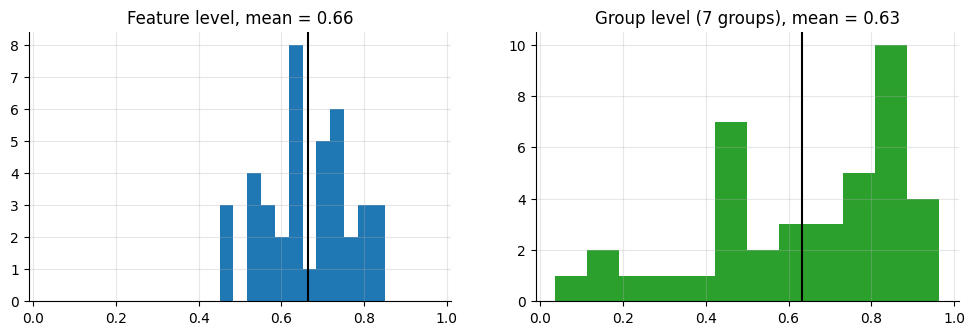

Feature level: mean rho = 0.664 (median 0.654, min 0.45, max 0.85)
Group level  : mean rho = 0.633 (median 0.696)
Mean local R2 of the 40 LIME surrogates: 0.724


In [26]:
# D4: LIME vs SHAP agreement on 40 random test days
rng = np.random.default_rng(SEED)
days = rng.choice(len(X_test), 40, replace=False)
fe_rho, gr_rho, r2s = [], [], []
fidx = {g: [feature_names.index(f) for f in fs] for g, fs in FEATURE_GROUPS.items()}
for t in days:
    x = X_test.iloc[t].values.astype(float)
    ex = new_lime(SEED + int(t))
    e = ex.explain_instance(x, predict_fn, num_features=len(feature_names), num_samples=5000)
    c, _ = lime_contrib(e, x, ex)
    phi = shap_exp.values[t]
    fe_rho.append(spearmanr(np.abs(c), np.abs(phi))[0])
    gc = np.array([c[ix].sum() for ix in fidx.values()]); gp = np.array([phi[ix].sum() for ix in fidx.values()])
    gr_rho.append(spearmanr(np.abs(gc), np.abs(gp))[0]); r2s.append(e.score)
fe_rho, gr_rho = np.array(fe_rho), np.array(gr_rho)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
axes[0].hist(fe_rho, bins=12, color="tab:blue"); axes[0].axvline(np.nanmean(fe_rho), color="k"); axes[0].set_title(f"Feature level, mean = {np.nanmean(fe_rho):.2f}")
axes[1].hist(gr_rho, bins=12, color="tab:green"); axes[1].axvline(np.nanmean(gr_rho), color="k"); axes[1].set_title(f"Group level (7 groups), mean = {np.nanmean(gr_rho):.2f}")
plt.show()
print(f"Feature level: mean rho = {np.nanmean(fe_rho):.3f} (median {np.nanmedian(fe_rho):.3f}, min {fe_rho.min():.2f}, max {fe_rho.max():.2f})")
print(f"Group level  : mean rho = {np.nanmean(gr_rho):.3f} (median {np.nanmedian(gr_rho):.3f})")
print(f"Mean local R2 of the 40 LIME surrogates: {np.mean(r2s):.3f}")

**D4 — Your answer:**

Over 40 random test days the mean Spearman correlation between |LIME contribution| and |SHAP| is 0.664 at feature level (median 0.654, range 0.45 to 0.85). At group level (7 groups) it is 0.633 (median 0.696), so summing per group does **not** raise agreement in the mean. With only seven items the ranks are coarse and a single swap changes the correlation a lot, so removing within-group noise is offset by that coarseness. The remaining disagreement is mostly methodological rather than correlated-feature splitting: LIME credit is a linear weight times the standardised distance from the *training mean*, fitted on neighbours that are mostly implausible (D2), while SHAP averages marginal contributions of the tree model including interactions. The surrogates themselves explain only a mean local R² of 0.724 of the model's local behaviour, which caps the agreement.

---
# Part E: A sequence model and attribution methods

### E1
Build input windows of **W = 14** days with **six channels** per step: scaled `log1p(PM2.5)`, `DEWP`, `PRES`, `Iws`, `doy_sin`, `doy_cos`. Fit all scalers on the training years only. Train a small LSTM or 1-D CNN with early stopping on 2013, and add its test MAE (µg/m³) to the table from B3.

windows  train (1082, 14, 6) | val (365, 14, 6) | test (365, 14, 6) | first test target: 2014-01-01
stopped at epoch 23, best epoch 8, best val MSE (scaled log) = 0.5805


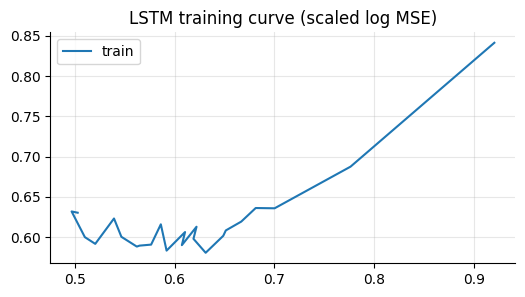

,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,44.98,67.19
LightGBM oracle (sees day-t weather),30.10,42.36
"LSTM (W=14, 6 channels)",45.75,65.00


In [27]:
W = 14
CHANNELS = ["log_pm", "DEWP", "PRES", "Iws", "doy_sin", "doy_cos"]
torch.set_num_threads(1)

# --- build per-day channels, scale with TRAINING-YEAR statistics only ---
doy = daily_clean.index.dayofyear
chan = pd.DataFrame({"log_pm": np.log1p(daily_clean["pm2.5"]), "DEWP": daily_clean["DEWP"], "PRES": daily_clean["PRES"],
                     "Iws": daily_clean["Iws"], "doy_sin": np.sin(2 * np.pi * doy / 365.25),
                     "doy_cos": np.cos(2 * np.pi * doy / 365.25)}, index=daily_clean.index)[CHANNELS]
mu, sd = chan.loc[:"2012-12-31"].mean(), chan.loc[:"2012-12-31"].std()          # fit on 2010-2012 only
chan_s = (chan - mu) / sd
inv_target = lambda ys: np.clip(np.expm1(np.asarray(ys) * sd["log_pm"] + mu["log_pm"]), 0, None)   # scaled log -> ug/m3

# --- windows: input = days t-W .. t-1, target = scaled log1p(PM2.5) of day t ---
vals = chan_s.values.astype(np.float32)
pos_t = np.arange(W, len(chan_s))
X_seq = np.stack([vals[p - W:p] for p in pos_t])                       # (n, W, 6)
y_seq = vals[pos_t, 0]                                                  # (n,)
dates = chan_s.index[pos_t]
m_tr, m_va, m_te = dates.year <= 2012, dates.year == 2013, dates.year == 2014
Xtr, ytr, Xva, yva, Xte, yte = X_seq[m_tr], y_seq[m_tr], X_seq[m_va], y_seq[m_va], X_seq[m_te], y_seq[m_te]
dates_te = dates[m_te]
print("windows  train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape, "| first test target:", dates_te[0].date())
assert (dates_te == X_test.index).all()                                 # same 2014 days as the LightGBM test set

class SeqForecaster(nn.Module):
    def __init__(self, n_in=len(CHANNELS), hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 24), nn.ReLU(), nn.Linear(24, 1))
    def forward(self, x):          # x: (batch, W, channels)
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)                        # (batch,)

T = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, ytr_t, Xva_t, yva_t, Xte_t = T(Xtr), T(ytr), T(Xva), T(yva), T(Xte)

torch.manual_seed(SEED)
model = SeqForecaster()
opt = torch.optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-4)
lossf = nn.MSELoss()
best, best_state, wait, PATIENCE, hist = np.inf, None, 0, 15, []
for epoch in range(200):
    model.train()
    perm = torch.randperm(len(Xtr_t))
    for b in range(0, len(perm), 64):
        ix = perm[b:b + 64]
        opt.zero_grad(); loss = lossf(model(Xtr_t[ix]), ytr_t[ix]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        tr_l, va_l = lossf(model(Xtr_t), ytr_t).item(), lossf(model(Xva_t), yva_t).item()
    hist.append((tr_l, va_l))
    if va_l < best - 1e-5: best, wait, best_state = va_l, 0, {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE: break
model.load_state_dict(best_state); model.eval()
print(f"stopped at epoch {epoch + 1}, best epoch {epoch + 1 - wait}, best val MSE (scaled log) = {best:.4f}")
for p_ in model.parameters(): p_.requires_grad_(False)

with torch.no_grad(): pred_seq_ug = inv_target(model(Xte_t).numpy())
results.loc["LSTM (W=14, 6 channels)"] = pd.Series(metrics(y_test_ug, pred_seq_ug))
plt.figure(figsize=(6, 3)); plt.plot(*zip(*hist)); plt.legend(["train", "val"]); plt.title("LSTM training curve (scaled log MSE)"); plt.show()
results.round(2)

**E1 — Your answer:**

The LSTM (48 hidden units, 14 × 6 windows, scalers fitted on 2010–2012 only) reaches a test MAE of 45.75 µg/m³ and RMSE of 65.00, compared with 44.98 / 67.19 for LightGBM and 52.75 / 75.71 for persistence. The two models are effectively tied: the LSTM is 0.77 worse in MAE but 2.19 better in RMSE, and both clearly beat the naive baselines. Early stopping on 2013 kept epoch 8 (stopped at epoch 23, best validation MSE 0.5805 in scaled log units), which shows how quickly a network overfits on only 1,082 training windows.

### E2
Implement **from scratch in PyTorch** (no Captum): Saliency, Gradient × Input, SmoothGrad and Integrated Gradients. Use the average training window as the IG baseline. Verify IG **completeness** numerically and report the mean gap. Then compute GradientSHAP with `shap.GradientExplainer` and 200 background windows.

In [28]:
BASELINE = Xtr_t.mean(0, keepdim=True)            # (1, W, C) average training window
C_ = len(CHANNELS)

def f(x):
    with torch.no_grad(): return model(x)

def _grad(x):
    """Gradient of the summed model output w.r.t. the input (one backward pass for the whole batch)."""
    x = x.clone().detach().requires_grad_(True)
    return torch.autograd.grad(model(x).sum(), x)[0]

def saliency(x):     return _grad(x).abs()
def grad_x_input(x): return _grad(x) * x

def smoothgrad(x, n=30, sigma=0.15):
    """Mean |gradient| over n noisy copies; noise std = sigma x (max - min) of each window."""
    g = torch.Generator().manual_seed(SEED)
    rng_ = (x.amax((1, 2), keepdim=True) - x.amin((1, 2), keepdim=True))
    acc = torch.zeros_like(x)
    for _ in range(n):
        acc += _grad(x + sigma * rng_ * torch.randn(x.shape, generator=g)).abs()
    return acc / n

def integrated_gradients(x, baseline=BASELINE, steps=64):
    """Riemann (midpoint) approximation of IG along the straight line baseline -> x."""
    diff = x - baseline
    acc = torch.zeros_like(x)
    for s in range(steps):
        a = (s + 0.5) / steps
        acc += _grad(baseline + a * diff)
    return diff * acc / steps

ATTR = {}
ATTR["Saliency"]        = saliency(Xte_t).numpy()
ATTR["Gradient x Input"] = grad_x_input(Xte_t).numpy()
ATTR["SmoothGrad"]      = smoothgrad(Xte_t).numpy()
ATTR["Integrated Gradients"] = integrated_gradients(Xte_t).numpy()

# completeness check: sum(IG) should equal f(x) - f(baseline)
ig_sum = ATTR["Integrated Gradients"].sum((1, 2))
delta = (f(Xte_t) - f(BASELINE)).numpy()
gap = np.abs(ig_sum - delta)
print(f"IG completeness (64 steps): mean |sum(IG) - (f(x)-f(baseline))| = {gap.mean():.4f}, max = {gap.max():.4f} "
      f"| mean |f(x)-f(baseline)| = {np.abs(delta).mean():.3f} (scaled log units)")
for st in [16, 256]:
    g_ = np.abs(integrated_gradients(Xte_t, steps=st).sum((1, 2)).numpy() - delta).mean()
    print(f"   with {st:3d} steps: mean gap = {g_:.4f}")
print(f"baseline prediction f(baseline) = {inv_target(f(BASELINE).numpy())[0]:.1f} ug/m3")

# GradientSHAP with 200 background windows
class _Wrap(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return self.m(x).unsqueeze(-1)            # shap expects (batch, n_outputs)
rs_ = np.random.RandomState(SEED)
bg = Xtr_t[torch.tensor(rs_.choice(len(Xtr_t), 200, replace=False))]
np.random.seed(SEED); torch.manual_seed(SEED)
gs_expl = shap.GradientExplainer(_Wrap(model), bg)
gs = gs_expl.shap_values(Xte_t, nsamples=200, rseed=SEED)
gs = np.asarray(gs[0] if isinstance(gs, list) else gs)
if gs.ndim == 4: gs = gs[..., 0]
ATTR["GradientSHAP"] = gs
with torch.no_grad(): f_bg = model(bg).mean().item()
print("GradientSHAP shape", gs.shape, "| completeness gap vs f(x)-E[f(bg)]: mean =",
      np.abs(gs.sum((1, 2)) - (f(Xte_t).numpy() - f_bg)).mean().round(4))

IG completeness (64 steps): mean |sum(IG) - (f(x)-f(baseline))| = 0.0004, max = 0.0066 | mean |f(x)-f(baseline)| = 0.501 (scaled log units)
   with  16 steps: mean gap = 0.0015
   with 256 steps: mean gap = 0.0001
baseline prediction f(baseline) = 69.1 ug/m3
GradientSHAP shape (365, 14, 6) | completeness gap vs f(x)-E[f(bg)]: mean = 0.0346


**E2 — Your answer:**

I implemented Saliency, Gradient × Input, SmoothGrad and Integrated Gradients (midpoint rule, 64 steps, average training window as baseline, whose prediction is 69.1 µg/m³). IG completeness holds well: the mean gap between ΣIG and f(x) − f(baseline) is 0.0004 (max 0.0066) against a mean |f(x) − f(baseline)| of 0.501 scaled log units, about 0.1%; it is 0.0015 with 16 steps and 0.0001 with 256, so it converges as expected. GradientSHAP with 200 background windows has a mean completeness gap of 0.0346, about 80 times larger than IG's, because it is a Monte Carlo estimate over random baselines and interpolation points and is only exact in expectation.

### E3
Implement **Occlusion** (window k = 2 days, all channels) and a **segment-based LIME** (7 segments of 2 days, baseline replacement, weighted ridge).

In [29]:
def occlusion(x, k=2, baseline=BASELINE):
    """Replace k consecutive days (all channels) by the baseline; credit = f(x) - f(occluded), shared equally by the k days."""
    out = torch.zeros(x.shape[0], x.shape[1])
    fx = f(x)
    for s in range(0, x.shape[1], k):
        xo = x.clone(); xo[:, s:s + k, :] = baseline[:, s:s + k, :]
        out[:, s:s + k] = ((fx - f(xo)) / k).unsqueeze(1)
    return out

def lime_segments(x, n_seg=7, n_samples=600, kernel_width=0.35, baseline=BASELINE, seed=SEED):
    """Segment-based LIME for ONE window x of shape (1, W, C): 7 segments of 2 days, baseline replacement, weighted ridge."""
    rng = np.random.default_rng(seed); seg = x.shape[1] // n_seg
    Z = rng.integers(0, 2, size=(n_samples, n_seg)); Z[0] = 1                    # first sample = the original window
    keep = torch.tensor(np.repeat(Z, seg, axis=1), dtype=torch.float32).unsqueeze(-1)     # (n_samples, W, 1)
    xp = x * keep + baseline * (1 - keep)
    y = f(xp).numpy()
    d = 1 - Z.mean(1)                                                             # fraction of segments removed
    w = np.exp(-(d ** 2) / kernel_width ** 2)
    coef = Ridge(alpha=1.0).fit(Z, y, sample_weight=w).coef_                      # effect of KEEPING each segment
    return torch.tensor(np.repeat(coef / seg, seg), dtype=torch.float32)         # spread over the segment's days

ATTR["Occlusion"]    = occlusion(Xte_t).numpy()
ATTR["Segment-LIME"] = torch.stack([lime_segments(Xte_t[i:i + 1], seed=SEED + i) for i in range(len(Xte_t))]).numpy()
print({k: v.shape for k, v in ATTR.items()})

{'Saliency': (365, 14, 6), 'Gradient x Input': (365, 14, 6), 'SmoothGrad': (365, 14, 6), 'Integrated Gradients': (365, 14, 6), 'GradientSHAP': (365, 14, 6), 'Occlusion': (365, 14), 'Segment-LIME': (365, 14)}


### E4
For the model's largest-error test day, plot:
- (a) the 14-day input history,
- (b) a methods × time-step heatmap of attributions summed over channels, normalised per row,
- (c) an Integrated Gradients **time × channel** heatmap.

Which channel and which day drove that forecast? Does the explanation agree with the domain hints?

> **Baseline question.** The average training window means "a typical fortnight of pollution and weather." Is this a sensible baseline for pollution, given its heavy right skew and strong winter/summer difference? Propose one alternative baseline and say how it would change the meaning of the attributions.

Largest-error day 2014-01-16: forecast 154.1 vs actual 457.5 ug/m3 | yesterday = 191.8


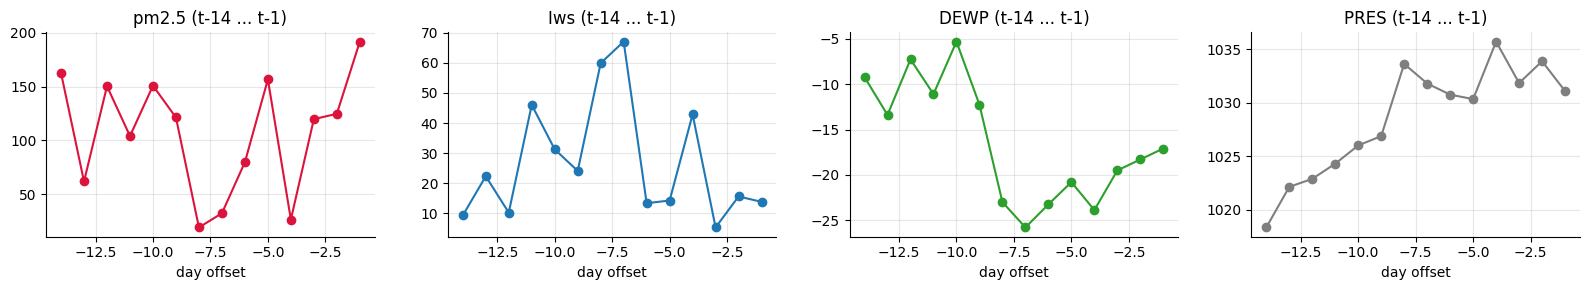

wind at t-1: cv | actual wind on target day: SE | actual Iws on target day: 13.9


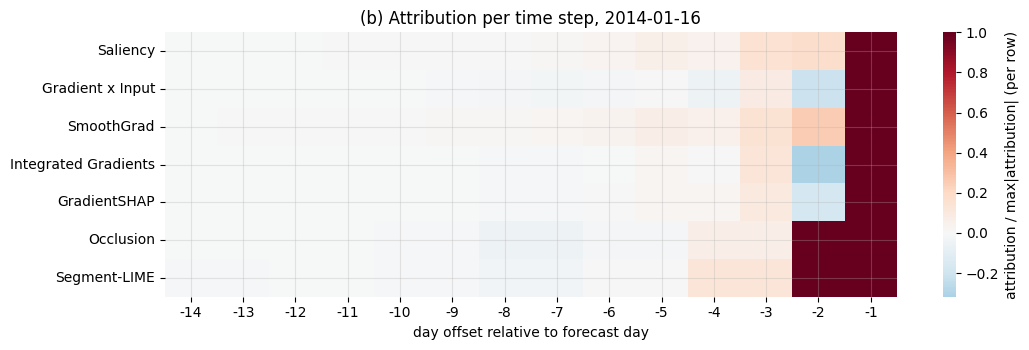

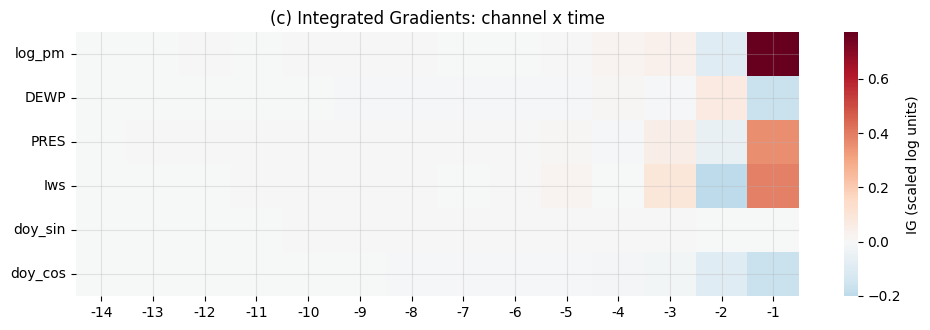

IG per channel (sum over time): {'log_pm': 0.7540000081062317, 'DEWP': -0.1420000046491623, 'PRES': 0.36500000953674316, 'Iws': 0.31299999356269836, 'doy_sin': 0.0010000000474974513, 'doy_cos': -0.32600000500679016}
IG per day (sum over channels), top 3 by |.|: {-1: 1.1710000038146973, -2: -0.3720000088214874, -3: 0.15600000321865082}
Largest single cell: day offset -1, channel log_pm, IG = 0.771
f(x) = 154.1 ug/m3, f(baseline) = 69.1 ug/m3

Seasonal baseline gives f(baseline) = 63.9 ug/m3 (vs 69.1); channel totals:
         IG, all-year baseline  IG, same-season baseline
log_pm                   0.754                     0.670
DEWP                    -0.142                    -0.024
PRES                     0.365                     0.074
Iws                      0.313                     0.366
doy_sin                  0.001                    -0.000
doy_cos                 -0.326                    -0.025


In [30]:
# E4: the LSTM's largest-error test day
err_seq = pred_seq_ug - y_test_ug
i_e = int(np.argmax(np.abs(err_seq))); day_e = dates_te[i_e]
print(f"Largest-error day {day_e.date()}: forecast {pred_seq_ug[i_e]:.1f} vs actual {y_test_ug[i_e]:.1f} ug/m3 | yesterday = {daily_clean['pm2.5'].iloc[daily_clean.index.get_loc(day_e) - 1]:.1f}")
hist_days = daily_clean.loc[day_e - pd.Timedelta(days=W): day_e - pd.Timedelta(days=1)]
lags = np.arange(-W, 0)

# (a) input history in original units
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, col, c in zip(axes, ["pm2.5", "Iws", "DEWP", "PRES"], ["crimson", "tab:blue", "tab:green", "tab:gray"]):
    ax.plot(lags, hist_days[col].values, "o-", color=c); ax.set_title(col + " (t-14 ... t-1)"); ax.set_xlabel("day offset")
plt.tight_layout(); plt.show()
print("wind at t-1:", hist_days["cbwd"].iloc[-1], "| actual wind on target day:", daily_clean.loc[day_e, "cbwd"], "| actual Iws on target day:", round(daily_clean.loc[day_e, "Iws"], 1))

# (b) methods x time-step heatmap, attributions summed over channels, normalised per row
def per_step(a):          # (n, W, C) or (n, W)  ->  (n, W) signed per-step attribution
    return a.sum(-1) if a.ndim == 3 else a
rows = {m: per_step(a)[i_e] for m, a in ATTR.items()}
H = pd.DataFrame(rows, index=lags).T
H_norm = H.div(H.abs().max(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(H_norm, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "attribution / max|attribution| (per row)"}); ax.set_xlabel("day offset relative to forecast day")
ax.set_title(f"(b) Attribution per time step, {day_e.date()}"); plt.tight_layout(); plt.show()

# (c) IG time x channel heatmap
ig_e = ATTR["Integrated Gradients"][i_e]
fig, ax = plt.subplots(figsize=(10, 3.4))
sns.heatmap(pd.DataFrame(ig_e.T, index=CHANNELS, columns=lags), cmap="RdBu_r", center=0, annot=False, ax=ax, cbar_kws={"label": "IG (scaled log units)"})
ax.set_title("(c) Integrated Gradients: channel x time"); plt.tight_layout(); plt.show()
ch_tot = pd.Series(ig_e.sum(0), index=CHANNELS); t_tot = pd.Series(ig_e.sum(1), index=lags)
print("IG per channel (sum over time):", ch_tot.round(3).to_dict())
print("IG per day (sum over channels), top 3 by |.|:", t_tot.reindex(t_tot.abs().sort_values(ascending=False).index).head(3).round(3).to_dict())
r_, c_ = np.unravel_index(np.abs(ig_e).argmax(), ig_e.shape); print(f"Largest single cell: day offset {lags[r_]}, channel {CHANNELS[c_]}, IG = {ig_e[r_, c_]:.3f}")
print(f"f(x) = {pred_seq_ug[i_e]:.1f} ug/m3, f(baseline) = {inv_target(f(BASELINE).numpy())[0]:.1f} ug/m3")

# Alternative baseline for the baseline question: the mean training window of the SAME calendar month (+-1)
mo = pd.DatetimeIndex(dates[m_tr]).month; mo_t = day_e.month
near = np.isin(mo, [(mo_t - 2) % 12 + 1, mo_t, mo_t % 12 + 1])
BASE_SEAS = Xtr_t[torch.tensor(near)].mean(0, keepdim=True)
ig_seas = integrated_gradients(Xte_t[i_e:i_e + 1], baseline=BASE_SEAS)[0].numpy()
cmp_b = pd.DataFrame({"IG, all-year baseline": ig_e.sum(0), "IG, same-season baseline": ig_seas.sum(0)}, index=CHANNELS).round(3)
print(f"\nSeasonal baseline gives f(baseline) = {inv_target(f(BASE_SEAS).numpy())[0]:.1f} ug/m3 (vs {inv_target(f(BASELINE).numpy())[0]:.1f}); channel totals:")
print(cmp_b.to_string())

**E4 — Your answer:**

The LSTM's largest error is on 2014-01-16: forecast 154.1 against 457.5 µg/m³ (yesterday 191.8). IG shows that day −1 drives the forecast (summed IG +1.171, against −0.372 for day −2), and the single largest cell is `log_pm` at day −1 (+0.771); by channel, `log_pm` is +0.754, `PRES` +0.365, `Iws` +0.313, `DEWP` −0.142 and `doy_cos` −0.326. This agrees with the domain hints for persistence, low wind and high pressure (all raising the forecast) and a drier dew point (lowering it), but the large negative `doy_cos` credit for a January day is counter-intuitive. The explanation cannot account for the miss, because the model never sees the stagnation that continued on day *t* (SE wind, Iws 13.9). **Baseline:** the all-year mean window (a "typical fortnight" with f = 69.1 µg/m³) mixes winter and summer, so a winter window looks unusual and the calendar channels absorb credit. With a same-season baseline (mean window of the same month ±1, f = 63.9 µg/m³) the `doy_cos` credit shrinks from −0.326 to −0.025, `PRES` from 0.365 to 0.074 and `DEWP` from −0.142 to −0.024, so the attributions then mean "what distinguishes this day from a typical January fortnight", not from an average year. A clean-air baseline would instead answer "why is this forecast polluted at all".

---
# Part F: Evaluating explanations

### F1 — agreement
Compute the mean per-instance Spearman correlation between the absolute per-time-step attributions of every pair of methods from Part E. Show it as a heatmap. Which methods form clusters, and why?

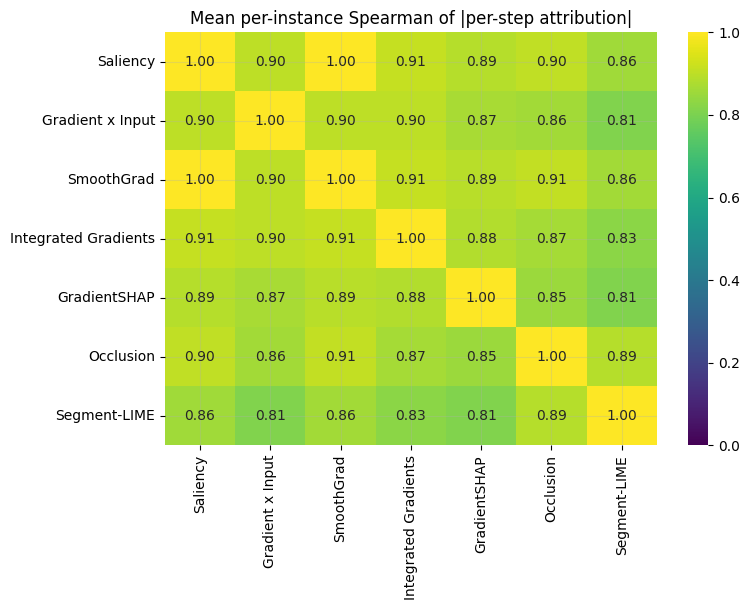

mean off-diagonal rho = 0.881 | min = 0.809 | max = 0.998
Highest: [('Saliency', 'SmoothGrad', np.float64(1.0)), ('SmoothGrad', 'Integrated Gradients', np.float64(0.91)), ('Saliency', 'Integrated Gradients', np.float64(0.91)), ('SmoothGrad', 'Occlusion', np.float64(0.91))]
Lowest : [('GradientSHAP', 'Segment-LIME', np.float64(0.81)), ('Gradient x Input', 'Segment-LIME', np.float64(0.81)), ('Integrated Gradients', 'Segment-LIME', np.float64(0.83)), ('GradientSHAP', 'Occlusion', np.float64(0.85))]


In [31]:
# F1: mean per-instance Spearman between the |per-step attributions| of all method pairs
STEP = {m: np.abs(per_step(a)) for m, a in ATTR.items()}
names = list(STEP)
Rho = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        r = [spearmanr(STEP[names[a]][i], STEP[names[b]][i])[0] for i in range(len(Xte))]
        Rho.iloc[a, b] = Rho.iloc[b, a] = np.nanmean(r)
fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(Rho, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax); ax.set_title("Mean per-instance Spearman of |per-step attribution|")
plt.tight_layout(); plt.show()
off = Rho.values[np.triu_indices(len(names), 1)]
print("mean off-diagonal rho =", off.mean().round(3), "| min =", off.min().round(3), "| max =", off.max().round(3))
pairs = [(names[a], names[b], Rho.iloc[a, b]) for a in range(len(names)) for b in range(a + 1, len(names))]
print("Highest:", [(a, b, round(r, 2)) for a, b, r in sorted(pairs, key=lambda t: -t[2])[:4]])
print("Lowest :", [(a, b, round(r, 2)) for a, b, r in sorted(pairs, key=lambda t: t[2])[:4]])

**F1 — Your answer:**

The mean off-diagonal Spearman correlation between methods is 0.881 (range 0.809 to 0.998), so all methods broadly agree on which days matter. Saliency and SmoothGrad are almost identical (0.998) because both are gradient magnitudes and SmoothGrad merely smooths them, and they are close to Integrated Gradients (both 0.91). The two segment-based perturbation methods are the most different from the signed gradient methods: Segment-LIME has the lowest correlations with GradientSHAP and Gradient × Input (0.81) and with IG (0.83). Two causes are the 2-day granularity, which creates ties and cannot rank neighbouring days, and the sampling noise of the 600-sample regression. The high overall agreement mostly reflects that the model's importance falls steeply with age, which is easy for every method to rank.

### F2 — faithfulness
Implement a **deletion** test (Most Relevant First) on the PM2.5 channel *and* an **insertion** test (start from the baseline and add the most relevant steps first). Include a **random** ordering as a control. Report normalised AUCs for every method in one table.

Plot the memory profile (mean |attribution| per time step over 2014, per method). Unlike the temperature model in the lecture, which had a one-day memory, does your test now separate the methods? Explain why or why not.

313 / 365 test windows have |f(x) - f(PM channel = baseline)| > 0.10 and enter the AUC averages
                      Deletion AUC (lower = better)  Insertion AUC (higher = better)  Insertion - Deletion
Gradient x Input                              0.026                            0.971                 0.944
GradientSHAP                                  0.026                            0.970                 0.944
Integrated Gradients                          0.027                            0.970                 0.943
Saliency                                      0.031                            0.966                 0.935
SmoothGrad                                    0.033                            0.964                 0.932
Occlusion                                     0.118                            0.877                 0.758
Segment-LIME                                  0.119                            0.875                 0.756
Random                                        0.

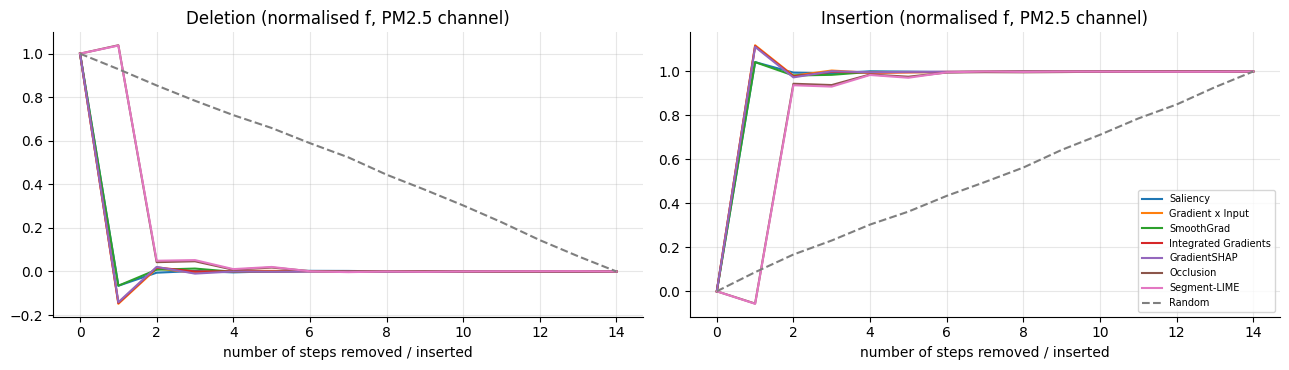

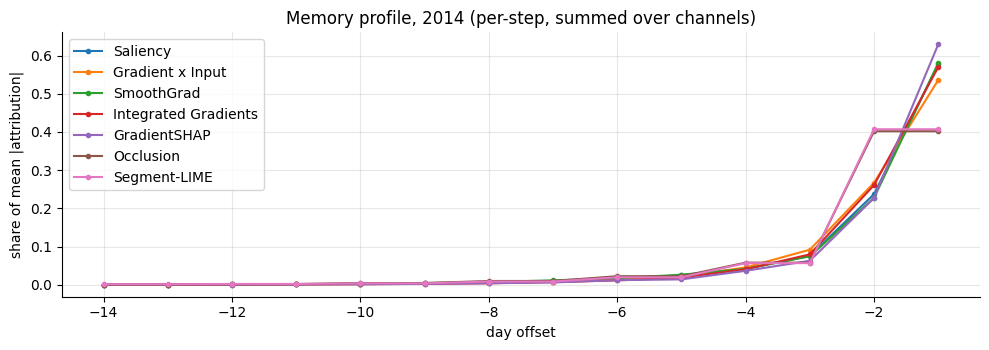

Share of attribution on the last day (t-1): {'Saliency': 0.58, 'Gradient x Input': 0.54, 'SmoothGrad': 0.58, 'Integrated Gradients': 0.57, 'GradientSHAP': 0.63, 'Occlusion': 0.4, 'Segment-LIME': 0.41}
Share on the last 3 days: {'Saliency': 0.89, 'Gradient x Input': 0.9, 'SmoothGrad': 0.88, 'Integrated Gradients': 0.91, 'GradientSHAP': 0.92, 'Occlusion': 0.86, 'Segment-LIME': 0.87}


In [32]:
def auc(c):                                     # trapezoid area over x in [0, 1]
    c = np.asarray(c, dtype=float); return float(np.sum((c[1:] + c[:-1]) / 2) / (len(c) - 1))

def deletion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    """Most-relevant-first deletion on the PM2.5 channel (index 0): f after replacing the top-k steps by the baseline."""
    xs = []
    for k in ks:
        xk = x.clone(); idx = list(order[:k]); xk[:, idx, 0] = baseline[:, idx, 0]; xs.append(xk)
    return f(torch.cat(xs)).numpy()

def insertion_curve(order, x, baseline=BASELINE, ks=range(0, W + 1)):
    """Start with the PM2.5 channel set to the baseline everywhere; put back the top-k most relevant steps."""
    xs = []
    for k in ks:
        xk = x.clone(); xk[:, :, 0] = baseline[:, :, 0]; idx = list(order[:k]); xk[:, idx, 0] = x[:, idx, 0]; xs.append(xk)
    return f(torch.cat(xs)).numpy()

# PM2.5-channel attribution per step: channel 0 for channel-resolved methods; the per-step value for Occlusion / Segment-LIME
PMSTEP = {m: np.abs(a[:, :, 0] if a.ndim == 3 else a) for m, a in ATTR.items()}
rng = np.random.default_rng(SEED)
f_full = f(Xte_t).numpy()
f_nopm = np.array([deletion_curve(np.arange(W), Xte_t[i:i + 1])[-1] for i in range(len(Xte))])     # PM channel fully baseline
effect = np.abs(f_full - f_nopm)
keep_i = np.where(effect > 0.10)[0]                                       # skip windows where removing PM2.5 changes nothing
print(f"{len(keep_i)} / {len(Xte)} test windows have |f(x) - f(PM channel = baseline)| > 0.10 and enter the AUC averages")

def norm_del(c):  return (c - c[-1]) / (c[0] - c[-1])                      # 1 -> 0
def norm_ins(c):  return (c - c[0]) / (c[-1] - c[0])                       # 0 -> 1
D, I, curvesD, curvesI = {}, {}, {}, {}
for m in list(PMSTEP) + ["Random"]:
    d_list, i_list, dc, ic = [], [], [], []
    for i in keep_i:
        x = Xte_t[i:i + 1]
        if m == "Random":
            cd = np.mean([norm_del(deletion_curve(rng.permutation(W), x)) for _ in range(10)], axis=0)
            ci = np.mean([norm_ins(insertion_curve(rng.permutation(W), x)) for _ in range(10)], axis=0)
        else:
            order = np.argsort(-PMSTEP[m][i], kind="stable")
            cd, ci = norm_del(deletion_curve(order, x)), norm_ins(insertion_curve(order, x))
        d_list.append(auc(cd)); i_list.append(auc(ci)); dc.append(cd); ic.append(ci)
    D[m], I[m] = np.mean(d_list), np.mean(i_list); curvesD[m], curvesI[m] = np.mean(dc, 0), np.mean(ic, 0)
faith = pd.DataFrame({"Deletion AUC (lower = better)": D, "Insertion AUC (higher = better)": I})
faith["Insertion - Deletion"] = faith.iloc[:, 1] - faith.iloc[:, 0]
print(faith.sort_values("Insertion - Deletion", ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for m in curvesD:
    axes[0].plot(range(W + 1), curvesD[m], label=m, ls="--" if m == "Random" else "-"); axes[1].plot(range(W + 1), curvesI[m], label=m, ls="--" if m == "Random" else "-")
axes[0].set_title("Deletion (normalised f, PM2.5 channel)"); axes[1].set_title("Insertion (normalised f, PM2.5 channel)")
for ax in axes: ax.set_xlabel("number of steps removed / inserted")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

# memory profile: mean |attribution| per time step over 2014, normalised to sum to 1
fig, ax = plt.subplots(figsize=(10, 3.6))
prof = pd.DataFrame({m: STEP[m].mean(0) / STEP[m].mean(0).sum() for m in STEP}, index=lags)
prof.plot(ax=ax, marker="o", ms=3); ax.set_xlabel("day offset"); ax.set_ylabel("share of mean |attribution|"); ax.set_title("Memory profile, 2014 (per-step, summed over channels)")
plt.tight_layout(); plt.show()
print("Share of attribution on the last day (t-1):", prof.loc[-1].round(2).to_dict())
print("Share on the last 3 days:", prof.loc[-3:].sum().round(2).to_dict())

**F2 — Your answer:**

On the 313 of 365 windows where removing the PM2.5 channel changes the forecast by more than 0.10, deletion / insertion AUCs are: Gradient × Input 0.026 / 0.971, GradientSHAP 0.026 / 0.970, IG 0.027 / 0.970, Saliency 0.031 / 0.966, SmoothGrad 0.033 / 0.964, Occlusion 0.118 / 0.877, Segment-LIME 0.119 / 0.875, and the random control 0.509 / 0.505. The test now **separates two families**, since gradient methods are about four times better on deletion than the 2-day-segment methods, but it does not separate methods inside the gradient family (differences ≤ 0.007). The memory profile explains why: the model has a short memory (the last day holds 54–63% of gradient attribution and the last three days 88–92%), so any method that ranks day *t−1* first scores almost perfectly, whereas Occlusion and Segment-LIME spread credit evenly across a 2-day block (40–41% on day *t−1*) and so cannot say which of the two days matters more. The gap is therefore partly a resolution effect, not purely a difference in faithfulness.

### F3 — channel-level faithfulness
Repeat the deletion test, but delete one whole **channel** at a time, ranked by each method's total channel attribution. Do the methods agree on whether wind or humidity matters more?

In [33]:
# F3: channel-level deletion. Channel-Occlusion supplies a channel score for the two methods that only resolve time.
def channel_occlusion(x, baseline=BASELINE):
    out = torch.zeros(x.shape[0], x.shape[2]); fx = f(x)
    for c in range(x.shape[2]):
        xo = x.clone(); xo[:, :, c] = baseline[:, :, c]; out[:, c] = fx - f(xo)
    return out.numpy()
CH = {m: np.abs(ATTR[m]).sum(1) for m in ["Saliency", "Gradient x Input", "SmoothGrad", "Integrated Gradients", "GradientSHAP"]}
CH["Channel-Occlusion"] = np.abs(channel_occlusion(Xte_t))

def channel_deletion(order, x, baseline=BASELINE):
    xs = []
    for k in range(C_ + 1):
        xk = x.clone(); idx = list(order[:k]); xk[:, :, idx] = baseline[:, :, idx]; xs.append(xk)
    return f(torch.cat(xs)).numpy()

fall = np.array([channel_deletion(np.arange(C_), Xte_t[i:i + 1])[-1] for i in range(len(Xte))])
keepc = np.where(np.abs(f_full - fall) > 0.10)[0]
res3 = {}
for m in list(CH) + ["Random"]:
    a_ = []
    for i in keepc:
        x = Xte_t[i:i + 1]
        if m == "Random": c = np.mean([norm_del(channel_deletion(rng.permutation(C_), x)) for _ in range(10)], axis=0)
        else:             c = norm_del(channel_deletion(np.argsort(-CH[m][i], kind="stable"), x))
        a_.append(auc(c))
    res3[m] = np.mean(a_)
ch_share = pd.DataFrame({m: pd.Series(CH[m].mean(0) / CH[m].mean(0).sum(), index=CHANNELS) for m in CH}).T
ch_share["Deletion AUC (lower = better)"] = pd.Series(res3)
ch_share["P(Iws ranked above DEWP)"] = {m: float((CH[m][:, CHANNELS.index("Iws")] > CH[m][:, CHANNELS.index("DEWP")]).mean()) for m in CH}
print(f"{len(keepc)} windows used")
print(ch_share.round(3).to_string())
print("Random control AUC:", round(res3["Random"], 3))

324 windows used
                      log_pm   DEWP   PRES    Iws  doy_sin  doy_cos  Deletion AUC (lower = better)  P(Iws ranked above DEWP)
Saliency               0.329  0.096  0.124  0.350    0.020    0.080                          0.208                     0.992
Gradient x Input       0.358  0.115  0.134  0.265    0.027    0.101                          0.174                     0.874
SmoothGrad             0.324  0.103  0.136  0.331    0.025    0.081                          0.192                     1.000
Integrated Gradients   0.372  0.103  0.135  0.277    0.019    0.094                          0.154                     0.929
GradientSHAP           0.393  0.112  0.143  0.231    0.020    0.101                          0.156                     0.841
Channel-Occlusion      0.413  0.085  0.157  0.166    0.025    0.153                          0.131                     0.729
Random control AUC: 0.518


**F3 — Your answer:**

All six channel-level scores agree that **wind matters more than humidity**: the mean share for `Iws` is 0.17 to 0.35 against 0.09 to 0.12 for `DEWP`, and `Iws` outranks `DEWP` in 73% (Channel-Occlusion) to 100% (SmoothGrad) of windows (IG 93%, GradientSHAP 84%, Gradient × Input 87%, Saliency 99%). They disagree on the top channel: Saliency and SmoothGrad rank `Iws` first (0.350 and 0.331 vs 0.329 and 0.324 for `log_pm`), while the signed methods rank `log_pm` first (IG 0.372, GradientSHAP 0.393, Channel-Occlusion 0.413). The deletion AUCs on 324 windows are Channel-Occlusion 0.131, IG 0.154, GradientSHAP 0.156, Gradient × Input 0.174, SmoothGrad 0.192, Saliency 0.208 and random 0.518. The signed methods beat the pure-sensitivity methods because magnitude of gradient ignores how far an input is from the baseline, while Channel-Occlusion's lead is partly circular, as it is the same operation as the test.

---
# Part G: Reflection
Answer in prose, 150–250 words each, citing your own results.

### G1
You must explain tomorrow's pollution forecast to a city health officer with no ML training. Which single explanation from this assignment would you show them, and what would you say? Which explanation would you *not* show, and why?

**G1 — Your answer:**

I would show the health officer one picture: a waterfall for the forecast itself, accompanied by the grouped SHAP bar chart. I would say: "The model expects 232 µg/m³ tomorrow. About half of its reasoning is that yesterday's heavy smog (325 µg/m³) carries over, which on its own pushes the forecast far above the usual level of about 72. About 40% comes from weather: light wind and no rain keep the smog in, whereas strong north-westerly wind and rain would clear it." These are the findings that are stable: SHAP's contributions add up exactly to the forecast (gap 1.4e-14), the weather directions match physics (wind −0.88, NW −0.82, rain −0.69), and PM history carries 51.2% of the credit against 42.5% for weather. I would translate log units to µg/m³ and be candid about the blind spot, since on 27 February the model predicted 112 where the actual value was 20 because the cold front arrived the same day. I would **not** show LIME or the LSTM attribution heatmaps. With 500 samples 13 features flip sign across seeds, 99.9% of LIME's neighbours are physically impossible, and on the polluted day the surrogate says 169 where the model says 232. The heatmaps depend on the baseline (the winter `doy_cos` credit of −0.326 vanishes with a seasonal baseline), which a non-specialist cannot interpret.

### G2
Name the two design choices that changed your explanations the most (for example target transform, baseline, feature grouping, number of LIME samples). Give the evidence from your notebook.

**G2 — Your answer:**

The two choices that changed my explanations most were the attribution **baseline** and the **number of LIME samples**. For the LSTM's worst day, switching from the all-year mean window to a same-season one changed the `doy_cos` credit from −0.326 to −0.025, `PRES` from +0.365 to +0.074, `DEWP` from −0.142 to −0.024 and the baseline forecast from 69.1 to 63.9 µg/m³; the explanation's story changed from "calendar and pressure" to "persistence and wind", although the model was identical. For LIME, going from 500 to 5,000 samples lowered the mean coefficient of variation of the top-8 weights from 0.27 to 0.08, raised the cross-seed rank correlation from 0.628 to 0.907 and removed the sign flip of `pm_lag_2` in the top 8. Two other choices were nearly as important: giving the model day *t*'s weather (the PM-history share drops from 51.2% to 28.0% in C6), and the log target, which puts every SHAP value in log units and makes the 71.7 µg/m³ base value a geometric-type average rather than the 98.1 µg/m³ mean. Grouping features mattered much less than expected: group-level LIME–SHAP agreement (0.633) was not better than feature-level (0.664).

### G3
Propose an explanation-based **drift alarm** for this model in production. State exactly what you would compute each week and the threshold you would use, then test it by comparing 2013 with 2014.

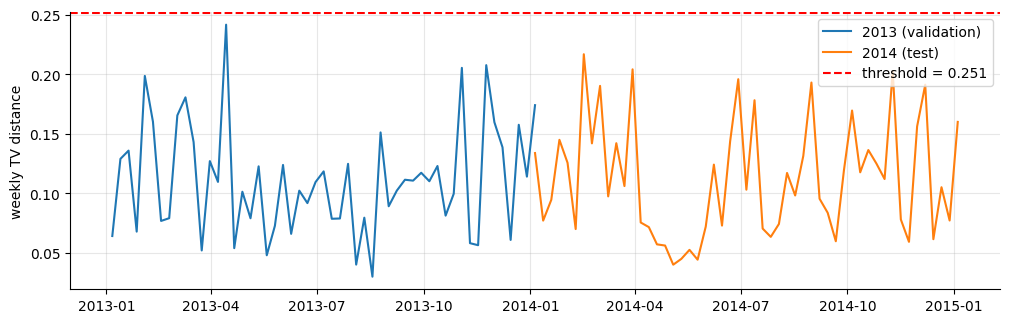

2013: mean D = 0.111 (sd 0.047) | 2014: mean D = 0.112 (sd 0.049) | Mann-Whitney p = 0.970
threshold = 0.251 | weeks above threshold: 2013 = 0, 2014 = 0 | alarms (2 consecutive weeks): 2013 = 0, 2014 = 0
Weather-group share of credit: training = 0.450 | 2013 = 0.461 | 2014 = 0.424
Largest 2014 weeks: {Timestamp('2014-02-16 00:00:00'): 0.217, Timestamp('2014-03-30 00:00:00'): 0.204, Timestamp('2014-11-09 00:00:00'): 0.203}


In [34]:
# G3: explanation-based drift alarm.
# Weekly statistic D_w = total-variation distance between this week's SHAP "credit share" vector over the 7 feature groups
# and the training-period (2010-2012) share vector for the same calendar month. Alarm: D_w above (2013 mean + 3 sd) for 2 consecutive weeks.
sv_tr, sv_va = tree_explainer(X_train), tree_explainer(X_val)
g_tr, g_va, g_te = grouped(sv_tr.values, index=X_train.index), grouped(sv_va.values, index=X_val.index), group_shap
def share_rows(a): return a.div(a.sum(1), axis=0)
ref = share_rows(g_tr.abs()).groupby(g_tr.index.month).mean()                         # month-specific reference shares
def weekly_stat(g):
    a = g.abs().resample("W").mean(); s = share_rows(a)
    d = 0.5 * np.abs(s.values - ref.loc[a.index.month].values).sum(1)
    return pd.Series(d, index=a.index), s
D13, s13 = weekly_stat(g_va); D14, s14 = weekly_stat(g_te)
thr = D13.mean() + 3 * D13.std()
def alarms(D): above = D > thr; return D.index[above & (above.shift(1, fill_value=False) | above.shift(-1, fill_value=False))]
a13, a14 = alarms(D13), alarms(D14)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(D13.index, D13.values, label="2013 (validation)"); ax.plot(D14.index, D14.values, label="2014 (test)")
ax.axhline(thr, color="r", ls="--", label=f"threshold = {thr:.3f}"); ax.set_ylabel("weekly TV distance"); ax.legend(); plt.show()
from scipy.stats import mannwhitneyu
print(f"2013: mean D = {D13.mean():.3f} (sd {D13.std():.3f}) | 2014: mean D = {D14.mean():.3f} (sd {D14.std():.3f}) | Mann-Whitney p = {mannwhitneyu(D13, D14).pvalue:.3f}")
print(f"threshold = {thr:.3f} | weeks above threshold: 2013 = {(D13 > thr).sum()}, 2014 = {(D14 > thr).sum()} | alarms (2 consecutive weeks): 2013 = {len(a13)}, 2014 = {len(a14)}")
wcols_ = ["Weather yesterday", "Weather change", "Wind direction"]
print(f"Weather-group share of credit: training = {share_rows(g_tr.abs().mean().to_frame().T)[wcols_].sum(1).iloc[0]:.3f} | 2013 = {share_rows(g_va.abs().mean().to_frame().T)[wcols_].sum(1).iloc[0]:.3f} | 2014 = {share_rows(g_te.abs().mean().to_frame().T)[wcols_].sum(1).iloc[0]:.3f}")
print("Largest 2014 weeks:", D14.sort_values(ascending=False).head(3).round(3).to_dict())

**G3 — Your answer:**

**Weekly computation:** score the week's forecasts with `TreeExplainer`, take the mean |SHAP| of each of the 7 feature groups, normalise to shares, and compute the total-variation distance D_w = ½ Σ|share_w − share_ref| to the training-period (2010–2012) share vector for the same calendar month (so normal seasonal changes do not trigger it). **Threshold:** mean + 3 standard deviations of D_w on the validation year 2013, which is 0.251; raise the alarm if two consecutive weeks exceed it. **Test:** 2013 has mean D = 0.111 (sd 0.047) and 2014 has 0.112 (sd 0.049), with a Mann–Whitney p = 0.970; no week exceeds the threshold in either year (the largest 2014 week is 0.217, in the week ending 2014-02-16), so there are 0 alarms. The weather share of total credit is 0.450 in training, 0.461 in 2013 and 0.424 in 2014. I conclude there is no explanation drift from 2013 to 2014: the model reasons in the same way, which is consistent with MAE staying near 45 µg/m³. Caveats: the threshold is calibrated on 2013 itself, the reference uses in-sample training SHAP, and a week of 7 days is noisy; the alarm detects a change in *how* the model reasons, so it complements, not replaces, monitoring of input distributions and error once the true values arrive.

---
# Bonus: pick up to two

- **Multi-horizon (5).** Forecast PM2.5 at t+1, t+3 and t+7 with three LightGBMs. Show how grouped SHAP shifts from lags to calendar and weather as the horizon grows.
- **TimeSHAP-style pruning (5).** For the sequence model, group all time steps older than *k* days into one "past" coalition and compute KernelSHAP on the reduced input. Find the smallest *k* that keeps 90% of the attribution.
- **Counterfactual (5).** For the most polluted test day, find the smallest change in yesterday's wind speed and direction that brings the forecast below 75 µg/m³ (China's 24-hour PM2.5 standard). Is the counterfactual physically plausible?

     LightGBM MAE  Persistence MAE
t+1         45.03            52.75
t+3         58.51            82.55
t+7         57.42            78.01

Share of mean |grouped SHAP| (%):
                       t+1   t+3   t+7
PM recent lags (1-3)  34.7   9.2   8.5
PM older lags (4-7)    4.7  15.5  16.0
PM rolling stats       4.8  12.4  19.0
Weather yesterday     24.4  24.9  16.1
Weather change         7.9   8.7  11.6
Wind direction        16.0   3.4   3.0
Calendar               7.5  25.9  25.9


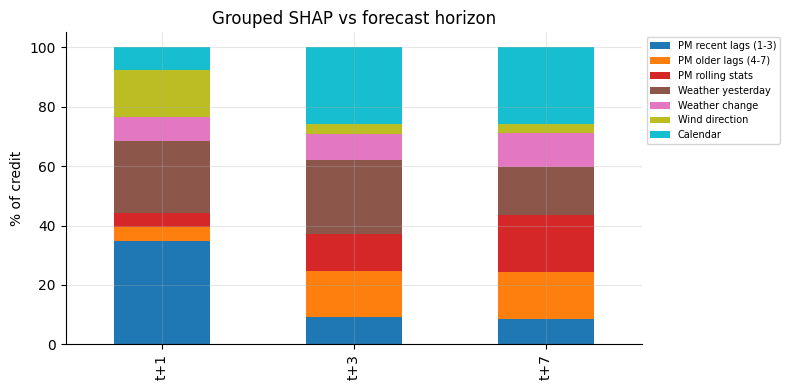


Most polluted forecast 2014-10-11: 232.2 ug/m3, yesterday wind = SE at Iws = 11.6, yesterday PM2.5 = 325.4
Lowest forecast reachable by changing ONLY yesterday's wind speed/direction:
dir
NE    156.0
NW    122.9
SE    158.4
cv    156.0
No wind-only counterfactual brings the forecast below 75 ug/m3.
  best wind (NW, Iws 57) + yesterday's PM2.5 scaled x1.0: forecast = 122.9 ug/m3
  best wind (NW, Iws 57) + yesterday's PM2.5 scaled x0.75: forecast = 118.2 ug/m3
  best wind (NW, Iws 57) + yesterday's PM2.5 scaled x0.5: forecast = 59.1 ug/m3
  best wind (NW, Iws 57) + yesterday's PM2.5 scaled x0.35: forecast = 56.8 ug/m3
  best wind (NW, Iws 57) + yesterday's PM2.5 scaled x0.25: forecast = 46.2 ug/m3
Observed range of Iws_lag_1 in training: 2.7 - 585.6 | share of training days with Iws_lag_1 > 100 and yesterday's PM2.5 > 300: 0.0009


In [35]:
# Bonus 1 (5 marks): multi-horizon forecasting, grouped SHAP vs horizon
def cal_feats(idx):
    doy_ = idx.dayofyear; md = idx.month * 100 + idx.day
    return {"doy_sin": np.sin(2 * np.pi * doy_ / 365.25), "doy_cos": np.cos(2 * np.pi * doy_ / 365.25),
            "is_heating_season": ((md >= 1115) | (md <= 315)).astype(int), "dow": idx.dayofweek}
mh_rows, mh_share = {}, {}
for h in [1, 3, 7]:
    Xh = data[feature_names].copy()
    for k, v in cal_feats(Xh.index + pd.Timedelta(days=h - 1)).items(): Xh[k] = v        # calendar of the TARGET day (known in advance)
    yh = data["target"].shift(-(h - 1))
    ok = yh.notna()
    parts = {}
    for nm, sl in [("tr", slice("2010", "2012")), ("va", slice("2013", "2013")), ("te", slice("2014", "2014"))]:
        xs_, ys_ = Xh.loc[sl][ok.loc[sl]], yh.loc[sl][ok.loc[sl]]
        if nm != "te": xs_, ys_ = xs_.iloc[:len(xs_) - (h - 1)], ys_.iloc[:len(ys_) - (h - 1)]    # drop rows whose label reaches into the next split
        parts[nm] = (xs_, ys_)
    # long horizons stop after 1 tree under early stopping (the 2013 loss rises immediately), so use a small, regularised, fixed-size model
    mh = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=40, colsample_bytree=0.7,
                           subsample=0.8, subsample_freq=1, reg_lambda=5.0, random_state=SEED, verbose=-1, deterministic=True,
                           force_row_wise=True, n_jobs=1).fit(*parts["tr"])
    xte_, yte_ = parts["te"]
    mh_rows[f"t+{h}"] = {"LightGBM MAE": mean_absolute_error(to_ugm3(yte_), to_ugm3(mh.predict(xte_))),
                         "Persistence MAE": mean_absolute_error(to_ugm3(yte_), xte_["pm_lag_1"])}
    sv_h = shap.TreeExplainer(mh)(xte_).values
    gh = grouped(sv_h, index=xte_.index).abs().mean(); mh_share[f"t+{h}"] = gh / gh.sum() * 100
print(pd.DataFrame(mh_rows).T.round(2).to_string()); sh_h = pd.DataFrame(mh_share).round(1); print("\nShare of mean |grouped SHAP| (%):"); print(sh_h.to_string())
sh_h.T.plot.bar(stacked=True, figsize=(8, 4), colormap="tab10"); plt.ylabel("% of credit"); plt.legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.title("Grouped SHAP vs forecast horizon"); plt.tight_layout(); plt.show()

# Bonus 2 (5 marks): counterfactual on yesterday's wind for the most polluted forecast
x0 = X_test.loc[[idx_high]].copy()
cur_dir = [c for c in WIND_CATS if x0[f"cbwd_{c}"].iloc[0] == 1][0]; sp0 = x0["Iws_lag_1"].iloc[0]
print(f"\nMost polluted forecast {idx_high.date()}: {to_ugm3(lgbm.predict(x0))[0]:.1f} ug/m3, yesterday wind = {cur_dir} at Iws = {sp0:.1f}, yesterday PM2.5 = {x0['pm_lag_1'].iloc[0]:.1f}")
grid = np.linspace(0, X_train["Iws_lag_1"].max(), 300); cf = []
for d_ in WIND_CATS:
    for sp in grid:
        xc = x0.copy(); xc["Iws_lag_1"] = sp
        for c_ in WIND_CATS: xc[f"cbwd_{c_}"] = int(c_ == d_)
        cf.append((d_, sp, to_ugm3(lgbm.predict(xc))[0]))
cf = pd.DataFrame(cf, columns=["dir", "Iws", "forecast"])
print("Lowest forecast reachable by changing ONLY yesterday's wind speed/direction:"); print(cf.groupby("dir")["forecast"].min().round(1).to_string())
feas = cf[cf.forecast < 75]
if len(feas):
    feas = feas.assign(cost=(feas.Iws - sp0).abs() / X_train["Iws_lag_1"].std() + (feas.dir != cur_dir)); print("Smallest feasible change:", feas.sort_values("cost").iloc[0].round(2).to_dict())
else:
    print("No wind-only counterfactual brings the forecast below 75 ug/m3.")
    # also move yesterday's PM2.5 (and the rolling means that contain it) proportionally to see how much of the problem is persistence
    best_ = cf.loc[cf.forecast.idxmin()]
    for fac in [1.0, 0.75, 0.5, 0.35, 0.25]:
        xc = x0.copy(); xc["Iws_lag_1"] = best_.Iws
        for c_ in WIND_CATS: xc[f"cbwd_{c_}"] = int(c_ == best_.dir)
        xc["pm_lag_1"] *= fac; xc["pm_roll_mean_3"] = xc[["pm_lag_1", "pm_lag_2", "pm_lag_3"]].mean(1)
        xc["pm_roll_mean_7"] = xc[[f"pm_lag_{k}" for k in range(1, 8)]].mean(1)
        print(f"  best wind ({best_.dir}, Iws {best_.Iws:.0f}) + yesterday's PM2.5 scaled x{fac}: forecast = {to_ugm3(lgbm.predict(xc))[0]:.1f} ug/m3")
print("Observed range of Iws_lag_1 in training:", round(float(X_train["Iws_lag_1"].min()), 1), "-", round(float(X_train["Iws_lag_1"].max()), 1),
      "| share of training days with Iws_lag_1 > 100 and yesterday's PM2.5 > 300:", round(float(((X_train.Iws_lag_1 > 100) & (X_train.pm_lag_1 > 300)).mean()), 4))

**Bonus answers.**

**Multi-horizon (5).** The long-horizon models stopped after 1 tree under early stopping, so all three horizons use one small regularised 200-tree LightGBM. Test MAE is 45.03 (t+1), 58.51 (t+3) and 57.42 µg/m³ (t+7), against persistence 52.75, 82.55 and 78.01; beyond one day the model is close to forecasting the seasonal average but remains much better than persistence. Grouped SHAP shifts as predicted: PM recent lags fall from 34.7% to 9.2% to 8.5%, wind direction (yesterday's wind says little about next week) from 16.0% to 3.4% to 3.0%, and calendar rises from 7.5% to 25.9% to 25.9%, with the slow rolling statistics rising from 4.8% to 12.4% to 19.0%.

**Counterfactual (5).** For the most polluted forecast (2014-10-11: 232.2 µg/m³, yesterday SE wind with Iws 11.6 and PM2.5 325.4), no change of yesterday's wind speed or direction brings the forecast below 75 µg/m³. The best reachable is 122.9 µg/m³ with NW wind at Iws ≈ 57 (NE 156.0, calm 156.0, SE 158.4). Reaching 59.1 µg/m³ needs yesterday's PM2.5 to be halved as well. This counterfactual is **not physically plausible**: a NW wind of that strength would have flushed the pollution, so a yesterday with strong NW wind and 325 µg/m³ barely exists (0.09% of training days have Iws > 100 and PM2.5 > 300). A valid counterfactual must change the PM history along with the wind, which shows the forecast is dominated by persistence.